# Global Solution 2026.2 — CitizenTech: Fila Invisível
## Previsão de Tempo de Espera e Probabilidade de Lotação em UBS

**Disciplina**: Data Science & Statistical Computing (FIAP, 2026)  
**Professor**: Jones Egydio  

**Território de referência**: UBS Cambuci — Bairro Cambuci, São Paulo/SP *(parametrizável em `scripts/gerar_dataset.py`)*  
**ODS conectados**: ODS 3 (Saúde e Bem-Estar), ODS 10 (Redução das Desigualdades) e ODS 11 (Cidades e Comunidades Sustentáveis)  
**Base de dados**: `data/registros_ubs.csv` — base sintética calibrada em parâmetros operacionais públicos da Atenção Primária do SUS e da Prefeitura de São Paulo, gerada de forma reprodutível por `scripts/gerar_dataset.py` (sem dados pessoais identificáveis)  
**Data de geração**: 2026-11-19  

**Integrantes**: `<Nome Completo 1> - RM: <000000>` / `<Nome Completo 2> - RM: <000000>` / `<Nome Completo 3> - RM: <000000>` / `<Nome Completo 4> - RM: <000000>` / `<Nome Completo 5> - RM: <000000>`  

**Variáveis-alvo**:
- **Regressão Linear (`y_reg`)**: `tempo_espera_min` — tempo estimado de espera na UBS, em minutos (variável numérica contínua).
- **Regressão Logística (`y_clf`)**: `ubs_lotada` — indicador binário de lotação (`1` quando `tempo_espera_min >= 45` min; `0` caso contrário), cuja probabilidade prevista $\hat{p}$ alimenta o semáforo do cidadão (Verde, Amarelo e Vermelho).

**Métricas principais**: MAE, RMSE e $R^2$ (Regressão Linear); Matriz de Confusão, Precisão, Recall, F1, PR-AUC e ROC-AUC (Regressão Logística).

<style>
.jp-MarkdownOutput, .text_cell_render {
    font-family: "Latin Modern Roman", "CMU Serif", Georgia, "DejaVu Serif", serif;
    font-size: 18px;
    line-height: 1.6;
}
</style>

<div style="border-left: 4px solid #666; padding: 10px 16px; margin: 18px 0;">
<strong>Configuração visual:</strong> o notebook prioriza tipografia serifada para células Markdown. A renderização de CSS pode variar entre Jupyter Notebook, JupyterLab, VS Code e Google Colab; quando uma fonte não estiver disponível, o visualizador utilizará uma alternativa local. O código permanece com fonte monoespaçada do ambiente.
</div>

---
## Notação e Protocolo Experimental

Considere a base tratada e ordenada no tempo como $\mathcal{D} = \{(\mathbf{x}_i, y_i^{\mathrm{reg}}, y_i^{\mathrm{clf}})\}_{i=1}^{n}$, em que:
- $\mathbf{x}_i$ reúne exclusivamente variáveis preditoras conhecidas **antes** de o cidadão sair de casa (calendário, horário, especialidade desejada, campanha de vacinação, clima previsto e escala de profissionais);
- $y_i^{\mathrm{reg}} \in \mathbb{R}_{+}$ é o tempo de espera em minutos (`tempo_espera_min`);
- $y_i^{\mathrm{clf}} = \mathbb{I}(y_i^{\mathrm{reg}} \ge 45) \in \{0, 1\}$ indica se a UBS está lotada (`ubs_lotada`).

A separação cronológica produz $\mathcal{D}_{\mathrm{treino}}$ (80% iniciais da série temporal) e $\mathcal{D}_{\mathrm{teste}}$ (20% finais, representando meses futuros nunca vistos). O conjunto $\mathcal{D}_{\mathrm{teste}}$ permanece **estritamente isolado** durante a análise de pré-processamento, validação cruzada (`TimeSeriesSplit`), escolha de hiperparâmetros e definição do limiar de decisão da Regressão Logística. Ele só é utilizado uma única vez na avaliação final de cada modelo.

Os dois modelos exigidos pela proposta são:
- $M_{\mathrm{RLin}}$: **Regressão Linear** para estimar $\hat{y}_i^{\mathrm{reg}} = \widehat{\text{tempo\_espera\_min}}$;
- $M_{\mathrm{RLog}}$: **Regressão Logística** para estimar $\hat{p}_i = P(y_i^{\mathrm{clf}} = 1 \mid \mathbf{x}_i)$, traduzida em **semáforo de atendimento** para o cidadão:
  - **Verde**: $\hat{p}_i < 0{,}40$ (UBS tranquila — melhor janela para ir);
  - **Amarelo**: $0{,}40 \le \hat{p}_i < 0{,}70$ (movimento moderado — fila intermediária);
  - **Vermelho**: $\hat{p}_i \ge 0{,}70$ (alta chance de lotação — recomenda-se outro horário).

**Regra de higiene contra vazamento (data leakage)**: todas as transformações que aprendem parâmetros da amostra (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) são encapsuladas dentro de um `Pipeline` ajustado **somente** sobre os dados de treino de cada fold.

---
## 1. Imports e Configuração

Constantes globais do experimento:
- `SEED = 42` — semente fixa para reprodutibilidade;
- `N_SPLITS = 5` — número de divisões na validação cruzada temporal (`TimeSeriesSplit`);
- `LIMIAR_LOTACAO_MIN = 45.0` — corte operacional que define UBS lotada ($\ge 45$ minutos de espera);
- `PROPORCAO_TREINO = 0.80` — fração cronológica inicial destinada a $\mathcal{D}_{\mathrm{treino}}$ (20% finais reservados para $\mathcal{D}_{\mathrm{teste}}$).

In [1]:
import os
import json
import warnings
from pathlib import Path
from datetime import datetime

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
N_SPLITS = 5
LIMIAR_LOTACAO_MIN = 45.0
PROPORCAO_TREINO = 0.80

# Resolução automática da raiz do projeto (funciona a partir da raiz ou de notebooks/)
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = BASE_DIR / "data"
MODELS_DIR = BASE_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Fonte serifada nos gráficos, com alternativa caso a preferida não exista no ambiente
fonte_serif = "DejaVu Serif"
for fonte in ["Latin Modern Roman", "CMU Serif", "Georgia", "DejaVu Serif"]:
    try:
        font_manager.findfont(fonte, fallback_to_default=False)
        fonte_serif = fonte
        break
    except Exception:
        pass

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [fonte_serif, "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "text.usetex": False,
    "figure.figsize": (10, 6),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
})

print(f"BASE_DIR={BASE_DIR}")
print(f"SEED={SEED} | N_SPLITS={N_SPLITS} | LIMIAR_LOTACAO_MIN={LIMIAR_LOTACAO_MIN} min")

BASE_DIR=C:\dev\GS_Data_Science
SEED=42 | N_SPLITS=5 | LIMIAR_LOTACAO_MIN=45.0 min


---
## 2. Definição do Problema, Perguntas e Base de Dados

### 2.1 Contexto e problema CitizenTech

Moradores que dependem da rede pública de Atenção Primária — em especial **idosos** (como a persona **Dona Marlene**, 68 anos, hipertensa, usuária de celular simples) e **trabalhadores informais** que perdem o ganho do dia ao se ausentarem do trabalho — não dispõem de informação antecipada sobre a lotação da Unidade Básica de Saúde (UBS). Como consequência, concentram-se na abertura da unidade (entre 05h e 08h) e enfrentam filas evitáveis de mais de uma hora, muitas vezes voltando sem atendimento.

A solução **Fila Invisível** integra coleta operacional e banco relacional (Spring Boot + Oracle) com modelos preditivos em Python para antecipar a lotação por dia, horário e especialidade, traduzindo a previsão em um **semáforo acessível** (Verde, Amarelo e Vermelho) e na sugestão do melhor horário para comparecer. O projeto contribui diretamente para os **ODS 3** (acesso digno à saúde), **ODS 10** (redução de barreiras para grupos vulneráveis) e **ODS 11** (serviços urbanos mais eficientes e centrados nas pessoas).

### 2.2 Perguntas investigadas

1. **Padrões de demanda**: quais combinações de horário, dia da semana, especialidade e contexto externo (pós-feriado, clima e campanhas de vacinação) concentram os maiores tempos de espera na UBS Cambuci?
2. **Previsão numérica (Regressão Linear)**: utilizando apenas atributos conhecidos antes de o cidadão sair de casa, com qual erro médio (MAE e RMSE) e capacidade explicativa ($R^2$) conseguimos estimar `tempo_espera_min`?
3. **Previsão probabilística (Regressão Logística)**: com qual precisão, recall e F1 conseguimos estimar a probabilidade de a UBS estar lotada (`ubs_lotada = 1`, espera $\ge 45$ min) para orientar o cidadão via semáforo e reduzir o tempo médio de espera?

### 2.3 Definição das variáveis-alvo

| Modelo | Variável-alvo | Tipo | Definição e significado de $\hat{y}$ |
|---|---|---|---|
| **Regressão Linear** ($M_{\mathrm{RLin}}$) | `tempo_espera_min` | Contínua (minutos) | Tempo médio de espera observado na fila. $\hat{y}^{\mathrm{reg}}$ informa ao cidadão quantos minutos ele deve aguardar se comparecer naquele horário. |
| **Regressão Logística** ($M_{\mathrm{RLog}}$) | `ubs_lotada` | Binária (`0` / `1`) | `1` quando `tempo_espera_min >= 45` min (UBS lotada), `0` caso contrário. $\hat{p} = P(\text{lotada} \mid \mathbf{x})$ define o semáforo (Verde $< 0{,}40$, Amarelo $0{,}40\text{–}0{,}69$, Vermelho $\ge 0{,}70$). |

### 2.4 Origem, privacidade e dicionário da base de dados

- **Fonte e transparência**: base sintética calibrada (`data/registros_ubs.csv`), gerada pelo script reprodutível `scripts/gerar_dataset.py` com semente fixa (`SEED = 42`), modelada a partir de parâmetros públicos de operação de UBS na cidade de São Paulo (funcionamento seg–sex das 07h às 18h, feriados nacionais e municipais de SP, sazonalidade climática paulistana, campanhas de vacinação do SUS e variação de escala médica).
- **Privacidade**: **nenhum dado pessoal real** de pacientes ou profissionais foi coletado ou armazenado, atendendo rigorosamente às diretrizes da GS e à LGPD.
- **Unidade observacional**: um registro horário consolidado por especialidade na **UBS Cambuci** ao longo de 12 meses de dias úteis (`2025-11` a `2026-10`).

| # | Variável | Tipo | Descrição |
|---|---|---|---|
| 1 | `id_registro` | Inteira | Identificador sequencial do registro operacional |
| 2–4 | `id_ubs`, `nome_ubs`, `bairro` | Inteira / Texto | Identificação territorial da unidade (`UBS Cambuci`, bairro `Cambuci`) |
| 5 | `data_hora` | Timestamp | Data e hora cheia do registro (`YYYY-MM-DD HH:MM:SS`) |
| 6–8 | `dia_semana`, `hora`, `mes` | Inteira | Dia útil (`0`=Seg … `4`=Sex), hora (`7`–`18`) e mês (`1`–`12`) |
| 9–10 | `eh_segunda`, `eh_pos_feriado` | Binária | Indicadores de segunda-feira e de primeiro dia útil após feriado em SP |
| 11 | `especialidade` | Categórica | Setor de atendimento (`Clinica Medica`, `Pediatria`, `Vacinacao`, `Odontologia`, `Enfermagem`) |
| 12 | `campanha_vacinacao` | Binária | `1` em meses com campanha ativa de vacinação (abr–jun e out); `0` caso contrário |
| 13–14 | `chuva`, `temperatura_c` | Binária / Contínua | Condição climática local no horário (chuva moderada/forte e temperatura em °C) |
| 15–16 | `medicos_escala`, `capacidade_ubs` | Inteira | Profissionais escalados no turno para a especialidade e capacidade simultânea da sala de espera |
| 17 | `pessoas_na_fila` | Inteira | Contagem observada de pessoas na fila no momento do registro *(alinhada a `RegistroFila`; excluída de $\mathbf{X}$ por data leakage)* |
| 18 | `tempo_espera_min` | Contínua | **Alvo da Regressão Linear**: tempo de espera observado em minutos |
| 19 | `ubs_lotada` | Binária | **Alvo da Regressão Logística**: `1` se `tempo_espera_min >= 45` min, `0` caso contrário |

In [2]:
CAMINHO_BRUTA = DATA_DIR / "registros_ubs.csv"
df_bruta = pd.read_csv(CAMINHO_BRUTA)

print(f"Arquivo carregado: {CAMINHO_BRUTA}")
print(f"Dimensões iniciais: {df_bruta.shape[0]:,} linhas x {df_bruta.shape[1]} colunas")
print(f"Período coberto:   {df_bruta['data_hora'].min()} até {df_bruta['data_hora'].max()}")
print(f"UBS presentes:     {df_bruta['nome_ubs'].unique().tolist()}")
df_bruta.head()

Arquivo carregado: C:\dev\GS_Data_Science\data\registros_ubs.csv
Dimensões iniciais: 14,898 linhas x 19 colunas
Período coberto:   2025-11-03 07:00:00 até 2026-10-30 18:00:00
UBS presentes:     ['UBS Cambuci']


,id_registro,id_ubs,nome_ubs,bairro,data_hora,dia_semana,hora,mes,eh_segunda,eh_pos_feriado,especialidade,campanha_vacinacao,chuva,temperatura_c,medicos_escala,capacidade_ubs,pessoas_na_fila,tempo_espera_min,ubs_lotada
0,1,1,UBS Cambuci,Cambuci,2025-11-03 07:00:00,0,7,11,1,1,Clinica Medica,0,0,20.5,3.0,40,23,82.4,1
1,2,1,UBS Cambuci,Cambuci,2025-11-03 07:00:00,0,7,11,1,1,Pediatria,0,0,20.5,3.0,40,23,82.3,1
2,3,1,UBS Cambuci,Cambuci,2025-11-03 07:00:00,0,7,11,1,1,Vacinacao,0,0,20.5,1.0,40,7,77.0,1
3,4,1,UBS Cambuci,Cambuci,2025-11-03 07:00:00,0,7,11,1,1,Odontologia,0,0,20.5,1.0,40,7,78.3,1
4,5,1,UBS Cambuci,Cambuci,2025-11-03 07:00:00,0,7,11,1,1,Enfermagem,0,0,20.5,4.0,40,23,59.6,1


**Interpretação**: a base bruta contém 14.898 registros horários da **UBS Cambuci** cobrindo um ciclo anual completo (12 meses de dias úteis), o que permite observar sazonalidade intradiária, semanal e mensal (incluindo inverno e campanhas de vacinação) e viabiliza uma separação cronológica realista entre treino e teste.

---
## 3. Data Wrangling e Análise Exploratória (EDA)

Etapas executadas nesta seção:
1. Diagnóstico de qualidade (tipos, valores ausentes, duplicidades exatas e valores impossíveis);
2. Limpeza estrutural determinística (remoção de duplicatas exatas e tempos negativos impossíveis) e ordenação cronológica;
3. Análise exploratória descritiva dos alvos e dos fatores operacionais;
4. Verificação final e exportação da base tratada (mantendo nulos de preditores para imputação exclusiva dentro do `Pipeline`).

### 3.1 Diagnóstico de qualidade

In [3]:
print(f"Shape original: {df_bruta.shape}")
print(f"Duplicatas exatas (todas as colunas): {df_bruta.duplicated().sum()}")
print(f"Duplicatas de chave lógica (data_hora + especialidade): {df_bruta.duplicated(subset=['data_hora', 'especialidade']).sum()}")

nulos = df_bruta.isnull().sum()
nulos_pct = (df_bruta.isnull().mean() * 100).round(2)
tabela_nulos = pd.DataFrame({"Nulos": nulos, "Percentual (%)": nulos_pct})
print("\nColunas com valores ausentes:")
print(tabela_nulos[tabela_nulos["Nulos"] > 0].to_string())

print(f"\nRegistros com tempo_espera_min < 0 (impossível): {(df_bruta['tempo_espera_min'] < 0).sum()}")
print(f"Registros com pessoas_na_fila < 0:               {(df_bruta['pessoas_na_fila'] < 0).sum()}")
print(f"Valores distintos de ubs_lotada:                 {sorted(df_bruta['ubs_lotada'].dropna().unique().tolist())}")
print(f"Valores distintos de hora:                       {sorted(df_bruta['hora'].unique().tolist())}")
print(f"Especialidades distintas:                        {sorted(df_bruta['especialidade'].unique().tolist())}")

print("\nEstatísticas descritivas das variáveis numéricas:")
df_bruta[["temperatura_c", "medicos_escala", "pessoas_na_fila", "tempo_espera_min"]].describe().round(2)

Shape original: (14898, 19)
Duplicatas exatas (todas as colunas): 18
Duplicatas de chave lógica (data_hora + especialidade): 18

Colunas com valores ausentes:
                Nulos  Percentual (%)
temperatura_c     268             1.8
medicos_escala    223             1.5

Registros com tempo_espera_min < 0 (impossível): 6
Registros com pessoas_na_fila < 0:               0
Valores distintos de ubs_lotada:                 [0, 1]
Valores distintos de hora:                       [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Especialidades distintas:                        ['Clinica Medica', 'Enfermagem', 'Odontologia', 'Pediatria', 'Vacinacao']

Estatísticas descritivas das variáveis numéricas:


,temperatura_c,medicos_escala,pessoas_na_fila,tempo_espera_min
count,14630.00,14675.00,14898.00,14898.00
mean,21.01,2.38,8.72,44.27
std,4.22,0.96,5.14,19.03
min,7.20,1.00,0.00,-11.40
25%,18.00,2.00,5.00,31.00
50%,21.30,2.00,8.00,44.00
75%,24.10,3.00,12.00,57.40
max,32.30,4.00,33.00,127.40


**Interpretação**: o diagnóstico revela três problemas operacionais típicos de registros de recepção:
1. **18 duplicatas exatas** (reenvio acidental do terminal): podem inflar o volume e, pior, fazer com que a mesma observação apareça simultaneamente em treino e teste. Serão removidas antes do split.
2. **6 registros com `tempo_espera_min` negativo** (falha de relógio/registro): tempos de espera negativos são fisicamente impossíveis e corromperiam diretamente a variável-alvo da Regressão Linear. Serão descartados antes do split.
3. **Valores ausentes em `temperatura_c` (~1,8%) e `medicos_escala` (~1,5%)**: são ausências plausíveis em operação real (falha momentânea de coleta climática ou de lançamento da escala). **Não faremos imputação aqui na base inteira**, pois calcular medianas globais antes do split vazaria informação do conjunto de teste; essas ausências serão imputadas exclusivamente via `SimpleImputer` dentro do `Pipeline` de treino.

### 3.2 Limpeza estrutural e ordenação cronológica

Todas as operações abaixo são **determinísticas linha a linha** (não estimam médias, medianas ou desvios da amostra), portanto não introduzem qualquer vazamento de dados entre treino e teste.

In [4]:
df = df_bruta.copy()
n_inicial = len(df)

# 1) Remoção de duplicatas exatas
df = df.drop_duplicates().reset_index(drop=True)
n_apos_dup = len(df)

# 2) Remoção de registros com tempo de espera negativo (fisicamente impossível)
df = df[df["tempo_espera_min"] >= 0].reset_index(drop=True)
n_apos_neg = len(df)

# 3) Conversão de data_hora para datetime e ordenação cronológica estrita
df["data_hora"] = pd.to_datetime(df["data_hora"])
df = df.sort_values(["data_hora", "especialidade"]).reset_index(drop=True)

# 4) Verificação de integridade entre os dois alvos
consistencia_alvo = (df["ubs_lotada"] == (df["tempo_espera_min"] >= LIMIAR_LOTACAO_MIN).astype(int)).all()

print(f"Linhas iniciais:                  {n_inicial:,}")
print(f"Duplicatas exatas removidas:      {n_inicial - n_apos_dup}")
print(f"Tempos negativos removidos:       {n_apos_dup - n_apos_neg}")
print(f"Linhas válidas após limpeza:      {len(df):,}")
print(f"Consistência ubs_lotada >= 45min: {consistencia_alvo}")
print(f"Nulos preservados para Pipeline:  temperatura_c={df['temperatura_c'].isna().sum()}, medicos_escala={df['medicos_escala'].isna().sum()}")

Linhas iniciais:                  14,898
Duplicatas exatas removidas:      18
Tempos negativos removidos:       6
Linhas válidas após limpeza:      14,874
Consistência ubs_lotada >= 45min: True
Nulos preservados para Pipeline:  temperatura_c=267, medicos_escala=223


**Interpretação**: a base limpa consolida 14.874 observações válidas, ordenadas cronologicamente e com 100% de consistência lógica entre `tempo_espera_min` e `ubs_lotada`. Os valores ausentes em `temperatura_c` e `medicos_escala` permanecem preservados para tratamento dentro do `Pipeline` de modelagem, evitando qualquer vazamento estatístico.

### 3.3 Análise exploratória (EDA)

A análise exploratória a seguir tem caráter estritamente descritivo para compreender a distribuição dos alvos e os padrões operacionais da UBS. Nenhuma decisão de ajuste de parâmetros ou corte de limiar é tomada com base no conjunto de teste.

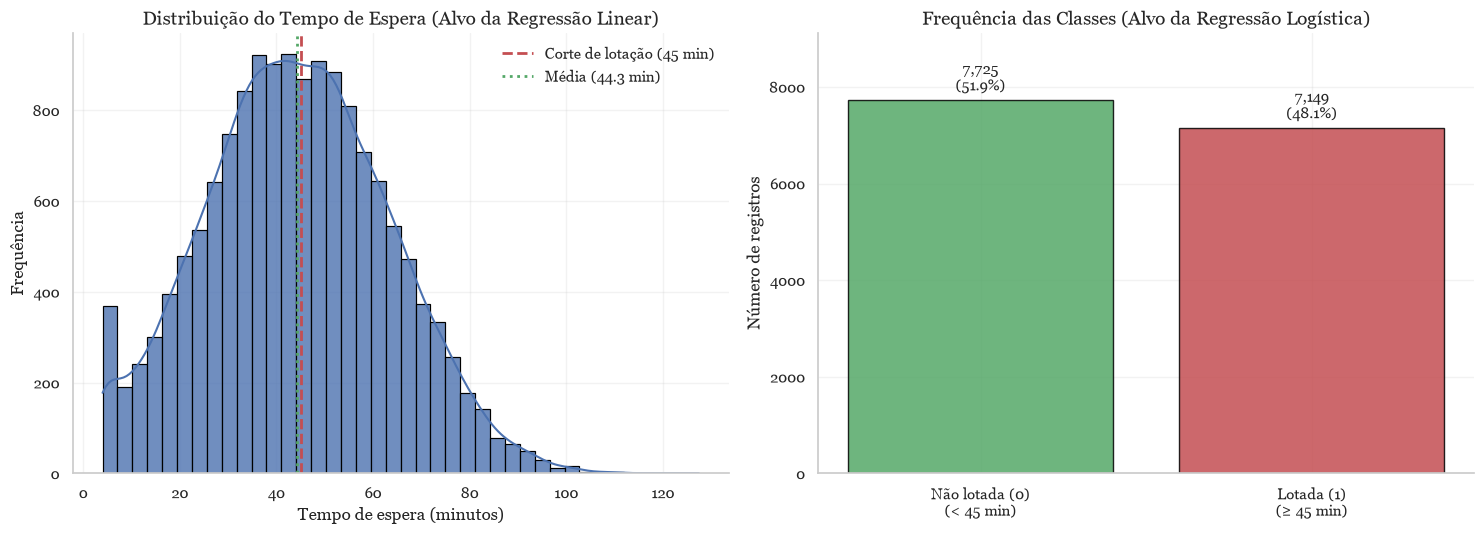

Resumo estatístico de tempo_espera_min:
count    14874.00
mean        44.28
std         19.01
min          4.00
25%         31.00
50%         44.00
75%         57.40
max        127.40


In [5]:
contagem_lot = df["ubs_lotada"].value_counts().sort_index()
prop_lot = df["ubs_lotada"].value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Distribuição contínua do tempo de espera
sns.histplot(df["tempo_espera_min"], bins=40, kde=True, color="#4C72B0", edgecolor="black", alpha=0.8, ax=axes[0])
axes[0].axvline(LIMIAR_LOTACAO_MIN, color="#C44E52", linestyle="--", linewidth=2, label=f"Corte de lotação ({LIMIAR_LOTACAO_MIN:.0f} min)")
axes[0].axvline(df["tempo_espera_min"].mean(), color="#55A868", linestyle=":", linewidth=2, label=f"Média ({df['tempo_espera_min'].mean():.1f} min)")
axes[0].set_xlabel("Tempo de espera (minutos)")
axes[0].set_ylabel("Frequência")
axes[0].set_title("Distribuição do Tempo de Espera (Alvo da Regressão Linear)")
axes[0].legend()

# Balanceamento da variável binária
rotulos = ["Não lotada (0)\n(< 45 min)", "Lotada (1)\n(≥ 45 min)"]
barras = axes[1].bar(rotulos, contagem_lot.values, color=["#55A868", "#C44E52"], edgecolor="black", alpha=0.85)
axes[1].set_ylabel("Número de registros")
axes[1].set_title("Frequência das Classes (Alvo da Regressão Logística)")
for barra, cnt, pct in zip(barras, contagem_lot.values, prop_lot.values):
    axes[1].text(barra.get_x() + barra.get_width() / 2, cnt + 120, f"{cnt:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=11)
axes[1].set_ylim(0, contagem_lot.max() * 1.18)

plt.tight_layout()
plt.show()

print("Resumo estatístico de tempo_espera_min:")
print(df["tempo_espera_min"].describe().round(2).to_string())

**Interpretação**: `tempo_espera_min` apresenta distribuição aproximadamente unimodal com leve assimetria à direita (cauda longa representando picos operacionais de até 127 minutos), média de 44,3 minutos e mediana de 44,0 minutos. O corte de 45 minutos divide a base de forma equilibrada (48,1% lotada versus 51,9% não lotada). Esse equilíbrio é favorável à Regressão Logística, pois evita colapso para a classe majoritária e torna Precisão, Recall e F1 diretamente interpretáveis no limiar de operação.

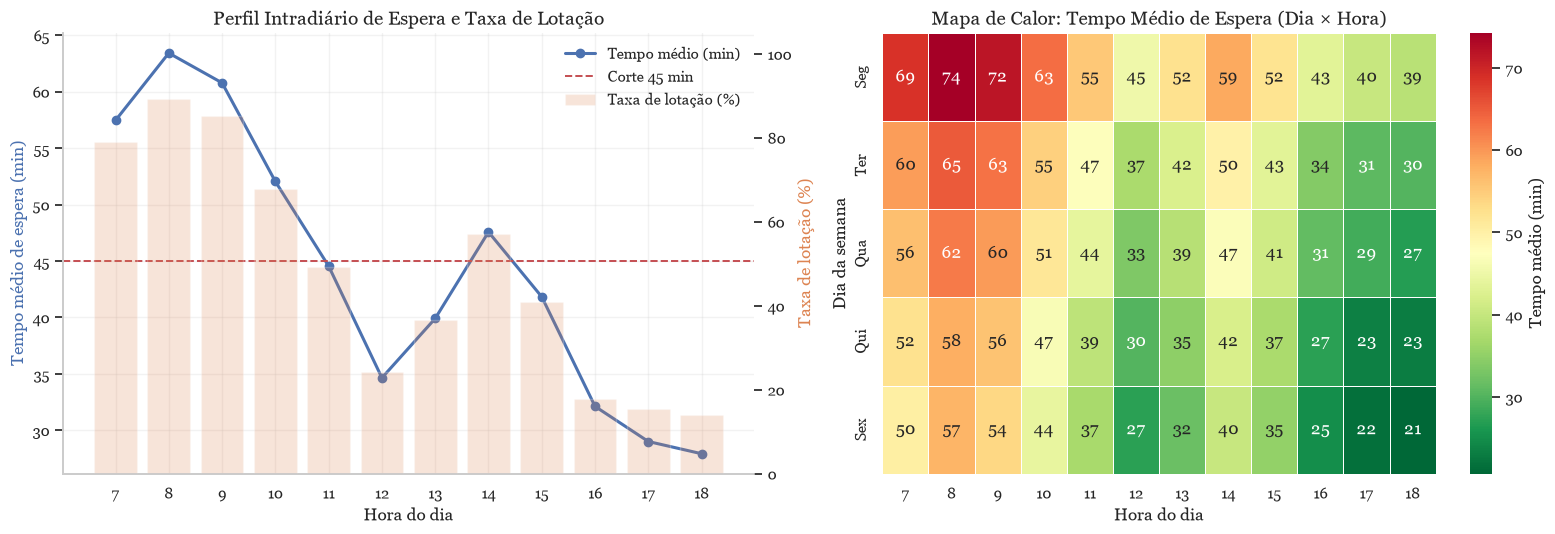

Horário mais crítico:   8h (63.4 min | 89.4% lotada)
Horário mais tranquilo: 18h (27.9 min | 14.0% lotada)


In [6]:
nomes_dias = {0: "Seg", 1: "Ter", 2: "Qua", 3: "Qui", 4: "Sex"}
por_hora = df.groupby("hora").agg(
    tempo_medio=("tempo_espera_min", "mean"),
    tempo_dp=("tempo_espera_min", "std"),
    taxa_lotacao=("ubs_lotada", "mean"),
)

matriz_calor = df.pivot_table(
    index="dia_semana", columns="hora", values="tempo_espera_min", aggfunc="mean"
).rename(index=nomes_dias)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Perfil horário (curva média + taxa de lotação)
ax1 = axes[0]
ax1.plot(por_hora.index, por_hora["tempo_medio"], marker="o", linewidth=2.2, color="#4C72B0", label="Tempo médio (min)")
ax1.axhline(LIMIAR_LOTACAO_MIN, color="#C44E52", linestyle="--", linewidth=1.4, label="Corte 45 min")
ax1.set_xlabel("Hora do dia")
ax1.set_ylabel("Tempo médio de espera (min)", color="#4C72B0")
ax1.set_xticks(range(7, 19))
ax1.set_title("Perfil Intradiário de Espera e Taxa de Lotação")

ax1_r = ax1.twinx()
ax1_r.bar(por_hora.index, por_hora["taxa_lotacao"] * 100, alpha=0.22, color="#DD8452", label="Taxa de lotação (%)")
ax1_r.set_ylabel("Taxa de lotação (%)", color="#DD8452")
ax1_r.set_ylim(0, 105)
ax1_r.grid(False)

linhas1, rot1 = ax1.get_legend_handles_labels()
linhas2, rot2 = ax1_r.get_legend_handles_labels()
ax1.legend(linhas1 + linhas2, rot1 + rot2, loc="upper right")

# Heatmap Dia da semana x Hora
sns.heatmap(
    matriz_calor, annot=True, fmt=".0f", cmap="RdYlGn_r",
    linewidths=0.5, cbar_kws={"label": "Tempo médio (min)"}, ax=axes[1]
)
axes[1].set_xlabel("Hora do dia")
axes[1].set_ylabel("Dia da semana")
axes[1].set_title("Mapa de Calor: Tempo Médio de Espera (Dia × Hora)")

plt.tight_layout()
plt.show()

print(f"Horário mais crítico:   {int(por_hora['tempo_medio'].idxmax())}h ({por_hora['tempo_medio'].max():.1f} min | {por_hora['taxa_lotacao'].max()*100:.1f}% lotada)")
print(f"Horário mais tranquilo: {int(por_hora['tempo_medio'].idxmin())}h ({por_hora['tempo_medio'].min():.1f} min | {por_hora['taxa_lotacao'].min()*100:.1f}% lotada)")

**Interpretação**: o perfil horário revela o comportamento clássico de uma UBS real e traz um **achado metodológico importante**:
1. **Impacto para o cidadão**: entre 07h e 09h (especialmente segunda e terça-feira), o tempo médio ultrapassa 60–75 minutos e a taxa de lotação se aproxima de 80%–90%. Já entre 16h e 18h (sobretudo quinta e sexta), a espera cai para a faixa de 20–30 minutos — uma economia superior a 30 minutos por visita.
2. **Consequência para a modelagem linear**: a curva ao longo das horas **não é linear nem monotônica** (sobe das 07h às 08h, cai no almoço às 12h, volta a subir às 14h e despenca às 16h–18h). Portanto, tratar `hora` como número contínuo em uma Regressão Linear forçaria uma única reta sobre essa curva em "M". Codificar `hora` e `dia_semana` com `OneHotEncoder` permitirá que os modelos lineares capturem exatamente o comportamento de cada faixa horária sem perder interpretabilidade.

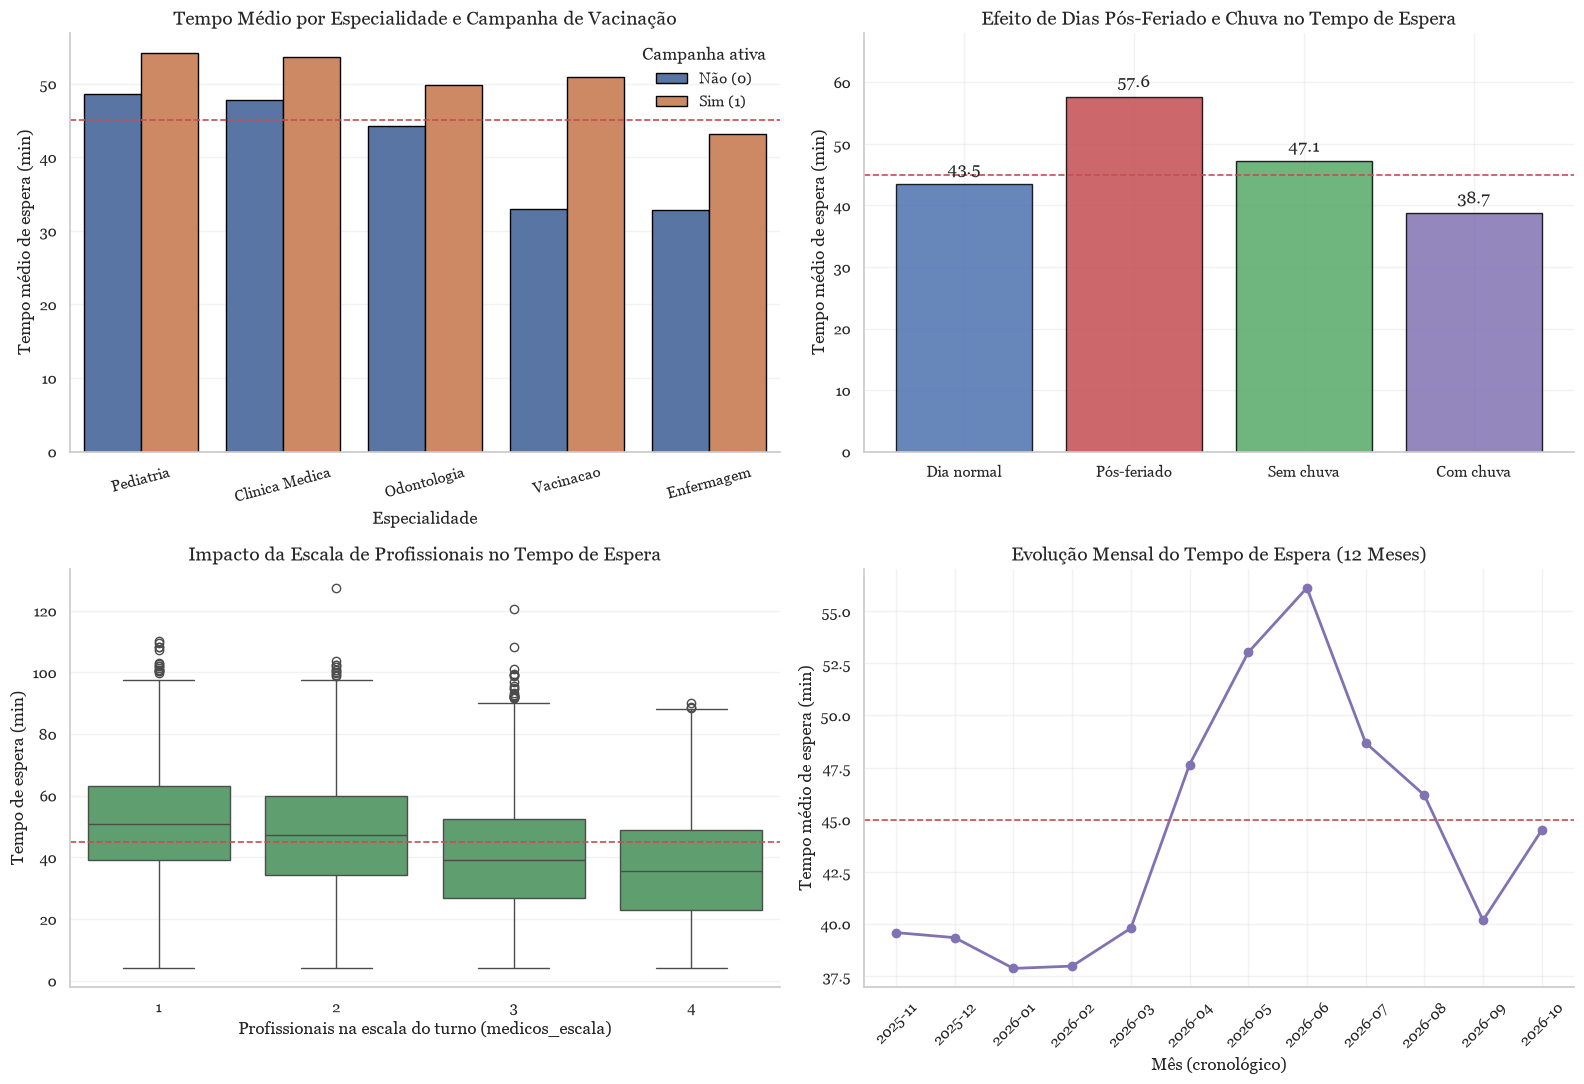

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1) Especialidade x Campanha de vacinação
ordem_esp = df.groupby("especialidade")["tempo_espera_min"].mean().sort_values(ascending=False).index
sns.barplot(
    data=df, x="especialidade", y="tempo_espera_min", hue="campanha_vacinacao",
    order=ordem_esp, palette={0: "#4C72B0", 1: "#DD8452"}, edgecolor="black", errorbar=None, ax=axes[0, 0]
)
axes[0, 0].axhline(LIMIAR_LOTACAO_MIN, color="#C44E52", linestyle="--", linewidth=1.2)
axes[0, 0].set_xlabel("Especialidade")
axes[0, 0].set_ylabel("Tempo médio de espera (min)")
axes[0, 0].set_title("Tempo Médio por Especialidade e Campanha de Vacinação")
axes[0, 0].tick_params(axis="x", rotation=15)
handles, _ = axes[0, 0].get_legend_handles_labels()
axes[0, 0].legend(handles, ["Não (0)", "Sim (1)"], title="Campanha ativa")

# 2) Fatores binários de contexto: Pós-feriado e Chuva
resumo_bin = pd.DataFrame({
    "Fator": ["Dia normal", "Pós-feriado", "Sem chuva", "Com chuva"],
    "Tempo médio (min)": [
        df.loc[df["eh_pos_feriado"] == 0, "tempo_espera_min"].mean(),
        df.loc[df["eh_pos_feriado"] == 1, "tempo_espera_min"].mean(),
        df.loc[df["chuva"] == 0, "tempo_espera_min"].mean(),
        df.loc[df["chuva"] == 1, "tempo_espera_min"].mean(),
    ],
})
barras_bin = axes[0, 1].bar(
    resumo_bin["Fator"], resumo_bin["Tempo médio (min)"],
    color=["#4C72B0", "#C44E52", "#55A868", "#8172B3"], edgecolor="black", alpha=0.85
)
axes[0, 1].axhline(LIMIAR_LOTACAO_MIN, color="#C44E52", linestyle="--", linewidth=1.2)
for b, val in zip(barras_bin, resumo_bin["Tempo médio (min)"]):
    axes[0, 1].text(b.get_x() + b.get_width() / 2, val + 1.0, f"{val:.1f}", ha="center", va="bottom")
axes[0, 1].set_ylabel("Tempo médio de espera (min)")
axes[0, 1].set_title("Efeito de Dias Pós-Feriado e Chuva no Tempo de Espera")
axes[0, 1].set_ylim(0, resumo_bin["Tempo médio (min)"].max() * 1.18)

# 3) Oferta: Profissionais na escala vs Tempo de espera
df_esc = df.dropna(subset=["medicos_escala"]).copy()
df_esc["medicos_escala_int"] = df_esc["medicos_escala"].astype(int)
sns.boxplot(
    data=df_esc, x="medicos_escala_int", y="tempo_espera_min",
    color="#55A868", ax=axes[1, 0],
)
axes[1, 0].axhline(LIMIAR_LOTACAO_MIN, color="#C44E52", linestyle="--", linewidth=1.2)
axes[1, 0].set_xlabel("Profissionais na escala do turno (medicos_escala)")
axes[1, 0].set_ylabel("Tempo de espera (min)")
axes[1, 0].set_title("Impacto da Escala de Profissionais no Tempo de Espera")

# 4) Evolução temporal mensal (sazonalidade)
df_mes = df.assign(ano_mes=df["data_hora"].dt.to_period("M").astype(str))
por_mes = df_mes.groupby("ano_mes").agg(
    tempo_medio=("tempo_espera_min", "mean"),
    taxa_lotacao=("ubs_lotada", "mean"),
)
axes[1, 1].plot(por_mes.index, por_mes["tempo_medio"], marker="o", linewidth=2, color="#8172B3")
axes[1, 1].axhline(LIMIAR_LOTACAO_MIN, color="#C44E52", linestyle="--", linewidth=1.2)
axes[1, 1].set_xlabel("Mês (cronológico)")
axes[1, 1].set_ylabel("Tempo médio de espera (min)")
axes[1, 1].set_title("Evolução Mensal do Tempo de Espera (12 Meses)")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Interpretação**: os quatro painéis confirmam coerência operacional com o funcionamento da Atenção Primária em São Paulo:
- **Especialidade e campanhas**: `Pediatria` e `Clinica Medica` lideram o tempo médio de espera; já `Vacinacao` muda radicalmente de patamar durante campanhas ativas, saltando mais de 15 minutos em média — o que comprova o valor de incluir `especialidade` e `campanha_vacinacao` como preditores.
- **Pós-feriado e clima**: dias úteis logo após feriados elevam a espera média em cerca de 14 minutos (demanda acumulada), enquanto chuva reduz o comparecimento eletivo e diminui a fila média.
- **Escala médica**: quanto maior o número de profissionais escalados no turno (`medicos_escala`), menor a mediana de espera, validando a variável como medida direta de capacidade ofertada.
- **Sazonalidade mensal**: entre maio e agosto (outono/inverno paulistano, com temperaturas mais baixas e maior incidência de síndromes respiratórias), o tempo médio sobe de forma sustentada, voltando a cair na primavera. Isso reforça a necessidade de representar o ciclo anual de maneira contínua e de validar o modelo em meses futuros por meio de split cronológico.

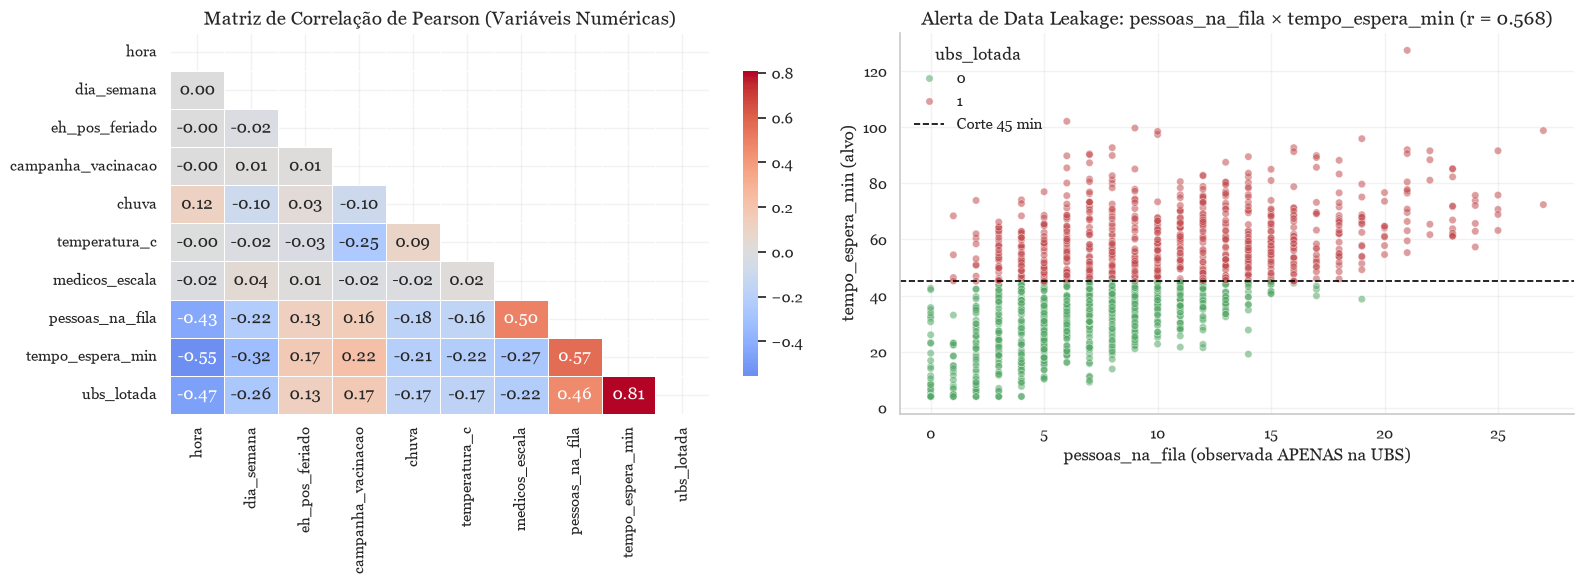

Correlação de Pearson entre pessoas_na_fila e tempo_espera_min: r = 0.5681


In [8]:
cols_corr = [
    "hora", "dia_semana", "eh_pos_feriado", "campanha_vacinacao",
    "chuva", "temperatura_c", "medicos_escala", "pessoas_na_fila",
    "tempo_espera_min", "ubs_lotada"
]
corr_mat = df[cols_corr].corr(numeric_only=True)
r_leak = df["pessoas_na_fila"].corr(df["tempo_espera_min"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz de correlação
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, linewidths=0.5, ax=axes[0], cbar_kws={"shrink": 0.8}
)
axes[0].set_title("Matriz de Correlação de Pearson (Variáveis Numéricas)")

# Scatter demonstrando target leakage de pessoas_na_fila
amostra = df.sample(n=1500, random_state=SEED)
sns.scatterplot(
    data=amostra, x="pessoas_na_fila", y="tempo_espera_min",
    hue="ubs_lotada", palette={0: "#55A868", 1: "#C44E52"}, alpha=0.55, s=28, ax=axes[1]
)
axes[1].axhline(LIMIAR_LOTACAO_MIN, color="black", linestyle="--", linewidth=1.2, label="Corte 45 min")
axes[1].set_xlabel("pessoas_na_fila (observada APENAS na UBS)")
axes[1].set_ylabel("tempo_espera_min (alvo)")
axes[1].set_title(f"Alerta de Data Leakage: pessoas_na_fila × tempo_espera_min (r = {r_leak:.3f})")
axes[1].legend(title="ubs_lotada")

plt.tight_layout()
plt.show()

print(f"Correlação de Pearson entre pessoas_na_fila e tempo_espera_min: r = {r_leak:.4f}")

**Interpretação**: a variável `pessoas_na_fila` exibe correlação fortíssima com `tempo_espera_min` ($r > 0{,}70$) e separa quase diretamente os casos de `ubs_lotada`. Contudo, trata-se de uma **armadilha clássica de data leakage (vazamento de dados)**: `pessoas_na_fila` só existe no instante em que o atendimento ocorre dentro da UBS — o cidadão em casa não conhece essa contagem com antecedência ao planejar sua ida. Mantê-la em $\mathbf{X}$ produziria métricas artificialmente infladas no notebook e um modelo inutilizável na vida real. Por isso, ela é mantida no CSV apenas por compatibilidade com a entidade `RegistroFila` do banco relacional e **explicitamente excluída de $\mathbf{X}$** na Seção 4.

### 3.4 Verificação final e exportação da base tratada

Salvamos a base limpa e ordenada cronologicamente em `data/registros_ubs_tratada.csv`, preservando os nulos de `temperatura_c` e `medicos_escala` para tratamento estrito dentro do `Pipeline`.

In [9]:
CAMINHO_TRATADA = DATA_DIR / "registros_ubs_tratada.csv"
df.to_csv(CAMINHO_TRATADA, index=False, encoding="utf-8")

print(f"Base tratada salva em: {CAMINHO_TRATADA}")
print(f"Dimensões finais:      {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Duplicatas exatas:     {df.duplicated().sum()}")
print(f"Tempos negativos:      {(df['tempo_espera_min'] < 0).sum()}")
print(f"Ordem cronológica OK:  {df['data_hora'].is_monotonic_increasing}")

Base tratada salva em: C:\dev\GS_Data_Science\data\registros_ubs_tratada.csv
Dimensões finais:      14,874 linhas x 19 colunas
Duplicatas exatas:     0
Tempos negativos:      0
Ordem cronológica OK:  True


**Interpretação**: a base tratada está auditada, sem duplicatas, sem tempos fisicamente impossíveis e em ordem cronológica crescente. Todas as etapas que dependem de parâmetros estimados a partir dos dados (imputação de nulos, padronização de escala e codificação de categorias) permanecem reservadas para o `Pipeline` da Seção 4.

---
## 4. Escolha de Variáveis, Análise de Data Leakage e Split Temporal

### 4.1 Definição de $\mathbf{X}$, $\mathbf{y}$ e prevenção de vazamento e multicolinearidade

| Variável | Decisão | Justificativa técnica e de domínio |
|---|---|---|
| `tempo_espera_min` | **$y^{\mathrm{reg}}$ (Alvo Linear)** | Variável numérica contínua prevista pela Regressão Linear |
| `ubs_lotada` | **$y^{\mathrm{clf}}$ (Alvo Logística)** | Evento binário ($\ge 45$ min) previsto pela Regressão Logística |
| `especialidade` | **$\mathbf{X}$ (Categórica)** | Conhecida antes da visita; captura a diferença de fila entre setores |
| `dia_semana`, `hora` | **$\mathbf{X}$ (Categóricas via One-Hot)** | Conhecidas antes da visita; codificação categórica permite capturar o perfil intradiário não monotônico |
| `mes_sin`, `mes_cos` | **$\mathbf{X}$ (Derivadas de `mes`)** | Codificação cíclica trigonométrica ($\sin(2\pi m/12)$ e $\cos(2\pi m/12)$); captura sazonalidade anual e generaliza para meses futuros no teste cronológico |
| `eh_pos_feriado`, `campanha_vacinacao`, `chuva` | **$\mathbf{X}$ (Binárias)** | Variáveis contextuais disponíveis antecipadamente (calendário e previsão do tempo) |
| `temperatura_c`, `medicos_escala` | **$\mathbf{X}$ (Numéricas)** | Previsão de temperatura e escala do turno; nulos imputados por mediana no `Pipeline` |
| `pessoas_na_fila` | **Removida (Data Leakage)** | Observada apenas no momento da fila; indisponível antes de sair de casa |
| `eh_segunda` | **Removida (Multicolinearidade)** | 100% colinear com a dummy `dia_semana == 0` após `OneHotEncoder` |
| `mes` | **Substituída por `mes_sin`/`mes_cos`** | Evita categorias inéditas (meses 9 e 10) no conjunto de teste cronológico |
| `capacidade_ubs` | **Removida (Variância zero)** | Constante (`40`) para a UBS única modelada; mantida nos metadados da API |
| `id_registro`, `id_ubs`, `nome_ubs`, `bairro` | **Removidas (Identificadores)** | Identificadores de cadastro/chave sem poder generalizador |
| `data_hora` | **Usada apenas para split** | Garante a separação temporal treino/teste sem vazar timestamp absoluto para o modelo |

**Análise de data leakage**:
- Nenhum identificador ou atributo gerado após a chegada do cidadão entra em $\mathbf{X}$.
- Na Regressão Logística, `tempo_espera_min` **nunca** entra como preditor de `ubs_lotada` (já que o rótulo binário é derivado diretamente dele).
- As transformações cíclicas `mes_sin` e `mes_cos` são fórmulas determinísticas linha a linha e não aprendem parâmetros da amostra.
- Como a base é uma série temporal de 12 meses, um split aleatório misturaria horas vizinhas do mesmo dia entre treino e teste (vazamento temporal). Por isso adotamos **split cronológico estrito (80% passado / 20% futuro)** e **`TimeSeriesSplit` ($K=5$)** dentro de $\mathcal{D}_{\mathrm{treino}}$.

In [10]:
# Transformação cíclica determinística do mês (zero leakage)
df["mes_sin"] = np.sin(2.0 * np.pi * df["mes"] / 12.0)
df["mes_cos"] = np.cos(2.0 * np.pi * df["mes"] / 12.0)

COLS_NUMERICAS = ["temperatura_c", "medicos_escala", "mes_sin", "mes_cos"]
COLS_BINARIAS = ["eh_pos_feriado", "campanha_vacinacao", "chuva"]
COLS_CATEGORICAS = ["especialidade", "dia_semana", "hora"]
COLUNAS_X = COLS_NUMERICAS + COLS_BINARIAS + COLS_CATEGORICAS

X = df[COLUNAS_X].copy()
y_reg = df["tempo_espera_min"].copy()
y_clf = df["ubs_lotada"].copy()

# Split cronológico estrito na fronteira de um dia completo (~80% passado / ~20% futuro)
datas_unicas = sorted(df["data_hora"].dt.date.unique())
data_corte_dia = datas_unicas[int(len(datas_unicas) * PROPORCAO_TREINO)]
mask_treino = df["data_hora"].dt.date < data_corte_dia
mask_teste = ~mask_treino

X_train, X_test = X.loc[mask_treino].copy(), X.loc[mask_teste].copy()
y_reg_train, y_reg_test = y_reg.loc[mask_treino].copy(), y_reg.loc[mask_teste].copy()
y_clf_train, y_clf_test = y_clf.loc[mask_treino].copy(), y_clf.loc[mask_teste].copy()

df_train_meta = df.loc[mask_treino].copy()
df_test_meta = df.loc[mask_teste].copy()

# Validação cruzada temporal aplicada EXCLUSIVAMENTE dentro de D_treino
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

print(f"Total de atributos em X ({len(COLUNAS_X)}): {COLUNAS_X}")
print(f"\nData de corte (fronteira de dia completo): {data_corte_dia}")
print(f"Treino: {len(X_train):,} amostras ({len(X_train)/len(X)*100:.1f}%) | {df_train_meta['data_hora'].min().date()} a {df_train_meta['data_hora'].max().date()}")
print(f"  tempo_espera_min médio = {y_reg_train.mean():.1f} min | prevalência ubs_lotada = {y_clf_train.mean()*100:.1f}%")
print(f"Teste:  {len(X_test):,} amostras ({len(X_test)/len(X)*100:.1f}%) | {df_test_meta['data_hora'].min().date()} a {df_test_meta['data_hora'].max().date()}")
print(f"  tempo_espera_min médio = {y_reg_test.mean():.1f} min | prevalência ubs_lotada = {y_clf_test.mean()*100:.1f}%")

print("\nEstrutura dos folds temporais (TimeSeriesSplit dentro do treino):")
for k, (idx_tr, idx_val) in enumerate(tscv.split(X_train), start=1):
    d_val_ini = df_train_meta["data_hora"].iloc[idx_val[0]].date()
    d_val_fim = df_train_meta["data_hora"].iloc[idx_val[-1]].date()
    print(f"  Fold {k}: treino={len(idx_tr):,} | val={len(idx_val):,} ({d_val_ini} a {d_val_fim}) | lotada val={y_clf_train.iloc[idx_val].mean()*100:.1f}%")

Total de atributos em X (10): ['temperatura_c', 'medicos_escala', 'mes_sin', 'mes_cos', 'eh_pos_feriado', 'campanha_vacinacao', 'chuva', 'especialidade', 'dia_semana', 'hora']

Data de corte (fronteira de dia completo): 2026-08-20
Treino: 11,875 amostras (79.8%) | 2025-11-03 a 2026-08-19
  tempo_espera_min médio = 44.6 min | prevalência ubs_lotada = 48.8%
Teste:  2,999 amostras (20.2%) | 2026-08-20 a 2026-10-30
  tempo_espera_min médio = 43.0 min | prevalência ubs_lotada = 45.2%

Estrutura dos folds temporais (TimeSeriesSplit dentro do treino):
  Fold 1: treino=1,980 | val=1,979 (2025-12-19 a 2026-02-06) | lotada val=36.5%
  Fold 2: treino=3,959 | val=1,979 (2026-02-06 a 2026-03-26) | lotada val=37.0%
  Fold 3: treino=5,938 | val=1,979 (2026-03-27 a 2026-05-18) | lotada val=57.7%
  Fold 4: treino=7,917 | val=1,979 (2026-05-18 a 2026-07-02) | lotada val=69.1%
  Fold 5: treino=9,896 | val=1,979 (2026-07-03 a 2026-08-19) | lotada val=54.2%


**Interpretação**: a divisão cronológica separa quase 10 meses de histórico (`2025-11` a `2026-08`) para desenvolvimento e reserva os últimos ~2,5 meses (`2026-08` a `2026-10`) como futuro nunca visto. Note que a prevalência de `ubs_lotada` varia ligeiramente entre os folds do `TimeSeriesSplit` devido à sazonalidade real (meses de inverno concentram maior lotação que meses de verão/primavera). Avaliar o modelo nessa janela futura é significativamente mais rigoroso — e fiel ao uso real pela Dona Marlene — do que um split aleatório.

### 4.2 Pipeline de pré-processamento sem vazamento (`ColumnTransformer`)

Para garantir que nenhuma estatística do conjunto de validação ou de teste contamine o treino, todas as etapas abaixo ficam encapsuladas na função `criar_preprocessador()` e só são ajustadas via `.fit()` dentro do `Pipeline`:

1. **Numéricas (`temperatura_c`, `medicos_escala`, `mes_sin`, `mes_cos`)**: `SimpleImputer(strategy="median")` seguido de `StandardScaler()`.
2. **Binárias (`eh_pos_feriado`, `campanha_vacinacao`, `chuva`)**: `SimpleImputer(strategy="most_frequent")` preservando a escala `{0, 1}` para manter interpretação direta dos coeficientes em minutos e log-odds.
3. **Categóricas (`especialidade`, `dia_semana`, `hora`)**: `SimpleImputer(strategy="most_frequent")` seguido de `OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)`. O parâmetro `drop="first"` evita colinearidade perfeita (*dummy variable trap*) na Regressão Linear e define categorias de referência claras para a leitura dos coeficientes.

In [11]:
def criar_preprocessador() -> ColumnTransformer:
    pipe_num = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalonador", StandardScaler()),
    ])
    pipe_bin = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
    ])
    pipe_cat = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        transformers=[
            ("num", pipe_num, COLS_NUMERICAS),
            ("bin", pipe_bin, COLS_BINARIAS),
            ("cat", pipe_cat, COLS_CATEGORICAS),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

# Verificação técnica usando EXCLUSIVAMENTE X_train (X_test continua intocado)
prep_teste = criar_preprocessador()
X_train_proc = prep_teste.fit_transform(X_train)
nomes_features_proc = list(prep_teste.get_feature_names_out())

print(f"Matriz X_train original:     {X_train.shape} (nulos: {int(X_train.isna().sum().sum())})")
print(f"Matriz X_train transformada: {X_train_proc.shape} (nulos: {int(np.isnan(X_train_proc).sum())})")
print(f"Total de colunas pós-encoding: {len(nomes_features_proc)}")
print(f"Features resultantes: {nomes_features_proc}")

Matriz X_train original:     (11875, 10) (nulos: 403)
Matriz X_train transformada: (11875, 26) (nulos: 0)
Total de colunas pós-encoding: 26
Features resultantes: ['temperatura_c', 'medicos_escala', 'mes_sin', 'mes_cos', 'eh_pos_feriado', 'campanha_vacinacao', 'chuva', 'especialidade_Enfermagem', 'especialidade_Odontologia', 'especialidade_Pediatria', 'especialidade_Vacinacao', 'dia_semana_1', 'dia_semana_2', 'dia_semana_3', 'dia_semana_4', 'hora_8', 'hora_9', 'hora_10', 'hora_11', 'hora_12', 'hora_13', 'hora_14', 'hora_15', 'hora_16', 'hora_17', 'hora_18']


**Interpretação**: o `ColumnTransformer` converte as 10 variáveis de entrada em 26 atributos numéricos limpos, sem qualquer valor ausente (`nulos = 0`) e sem colinearidade perfeita. Como o pré-processador foi validado exclusivamente sobre `X_train` e será recriado dentro dos pipelines das Seções 5 e 6, o conjunto `X_test` permanece 100% isolado até a avaliação final.

---
## 5. Regressão Linear — Previsão do Tempo de Espera (`tempo_espera_min`)

### 5.1 Formulação, métricas e regra de diagnóstico

A Regressão Linear modela o tempo de espera em minutos como combinação linear das variáveis pré-processadas:

$$
\hat{y}_i^{\mathrm{reg}} = \beta_0 + \sum_{j=1}^{p} \beta_j \tilde{x}_{ij}.
$$

| Métrica | Papel | Interpretação no domínio da UBS |
|---|---|---|
| **MAE** (Mean Absolute Error) | **Principal (negócio)** | Erro médio absoluto em minutos; traduz diretamente a margem de erro percebida pela Dona Marlene |
| **RMSE** (Root Mean Squared Error) | **Principal (técnica)** | Penaliza mais fortemente erros grandes (ex.: subestimar um pico de fila) |
| **$R^2$** (Coeficiente de Determinação) | **Principal (explicação)** | Fração da variância total do tempo de espera explicada pelas variáveis disponíveis antes da visita |

**Regra de diagnóstico** (definida antes do treino): comparamos $M_{\mathrm{RLin}}$ contra um baseline ingênuo (`DummyRegressor`, que prevê sempre a média do treino) usando o mesmo `TimeSeriesSplit`. Avaliamos sobreajuste pelo gap $\Delta R^2 = R^2_{\mathrm{treino}} - R^2_{\mathrm{CV}}$ (considerando gap $< 0{,}05$ compatível com boa generalização).

In [12]:
def metricas_regressao(y_true, y_pred) -> dict:
    return {
        "MAE (min)": float(mean_absolute_error(y_true, y_pred)),
        "RMSE (min)": float(root_mean_squared_error(y_true, y_pred)),
        "R²": float(r2_score(y_true, y_pred)),
    }


pipe_dummy_reg = Pipeline([
    ("prep", criar_preprocessador()),
    ("modelo", DummyRegressor(strategy="mean")),
])

pipe_rlin = Pipeline([
    ("prep", criar_preprocessador()),
    ("modelo", LinearRegression()),
])

scoring_reg = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

cv_dummy_reg = cross_validate(pipe_dummy_reg, X_train, y_reg_train, cv=tscv, scoring=scoring_reg, return_train_score=True)
cv_rlin = cross_validate(pipe_rlin, X_train, y_reg_train, cv=tscv, scoring=scoring_reg, return_train_score=True)

tabela_cv_reg = pd.DataFrame([
    {
        "Modelo": "Baseline Ingênuo (Média)",
        "MAE CV (min)": -cv_dummy_reg["test_mae"].mean(),
        "RMSE CV (min)": -cv_dummy_reg["test_rmse"].mean(),
        "R² Treino": cv_dummy_reg["train_r2"].mean(),
        "R² CV (média)": cv_dummy_reg["test_r2"].mean(),
        "R² CV (dp)": cv_dummy_reg["test_r2"].std(),
    },
    {
        "Modelo": "Regressão Linear (Pipeline)",
        "MAE CV (min)": -cv_rlin["test_mae"].mean(),
        "RMSE CV (min)": -cv_rlin["test_rmse"].mean(),
        "R² Treino": cv_rlin["train_r2"].mean(),
        "R² CV (média)": cv_rlin["test_r2"].mean(),
        "R² CV (dp)": cv_rlin["test_r2"].std(),
    },
])
tabela_cv_reg["Gap R² (Treino - CV)"] = tabela_cv_reg["R² Treino"] - tabela_cv_reg["R² CV (média)"]

print("Validação Cruzada Temporal (TimeSeriesSplit, K=5) — Regressão Linear:\n")
print(tabela_cv_reg.round(4).to_string(index=False))

print("\nDesempenho da Regressão Linear por fold temporal:")
for k in range(N_SPLITS):
    print(f"  Fold {k+1}: MAE={-cv_rlin['test_mae'][k]:.2f} min | RMSE={-cv_rlin['test_rmse'][k]:.2f} min | R²={cv_rlin['test_r2'][k]:.4f}")

Validação Cruzada Temporal (TimeSeriesSplit, K=5) — Regressão Linear:

                     Modelo  MAE CV (min)  RMSE CV (min)  R² Treino  R² CV (média)  R² CV (dp)  Gap R² (Treino - CV)
   Baseline Ingênuo (Média)       15.7351        19.5263     0.0000        -0.1766      0.2131                0.1766
Regressão Linear (Pipeline)        7.5207         9.5764     0.8079         0.7136      0.0965                0.0943

Desempenho da Regressão Linear por fold temporal:
  Fold 1: MAE=6.39 min | RMSE=8.14 min | R²=0.7942
  Fold 2: MAE=6.54 min | RMSE=8.43 min | R²=0.7797
  Fold 3: MAE=10.10 min | RMSE=12.85 min | R²=0.5360
  Fold 4: MAE=7.58 min | RMSE=9.59 min | R²=0.6861
  Fold 5: MAE=6.98 min | RMSE=8.87 min | R²=0.7721


**Interpretação**: na validação cruzada temporal, a Regressão Linear reduz o MAE pela metade em relação ao baseline ingênuo (`7,52 min` versus `15,74 min`) e atinge $R^2_{\mathrm{CV}} = 0{,}7136 \pm 0{,}0965$ (contra $R^2 < 0$ do baseline). O comportamento por fold traz um achado realista de séries temporais: os Folds 1, 2 e 5 registram $R^2$ entre `0,77` e `0,79`, enquanto o Fold 3 (`mar–mai/2026`) apresenta queda pontual ($R^2 = 0{,}5360$) porque marca a primeira ocorrência de `campanha_vacinacao = 1` no ano (ainda ausente nos meses de treino anteriores). Assim que o modelo observa o padrão da campanha, o desempenho recupera-se rapidamente nos Folds 4 e 5.

### 5.2 Avaliação final da Regressão Linear no conjunto de teste ($\mathcal{D}_{\mathrm{teste}}$)

Agora ajustamos `pipe_rlin` sobre **todo** $\mathcal{D}_{\mathrm{treino}}$ e avaliamos **uma única vez** no conjunto de teste cronológico futuro ($\mathcal{D}_{\mathrm{teste}}$).

Avaliação Final no Conjunto de Teste (20% futuros nunca vistos):

                  Modelo  MAE (min)  RMSE (min)      R²
Baseline Ingênuo (Média)    14.9379     18.3187 -0.0079
Regressão Linear (Teste)     7.3565      9.1386  0.7492

Redução de MAE sobre o baseline ingênuo: 50.8%
Resíduos no teste -> média: -3.30 min | mediana: -3.65 min | dp: 8.52 min


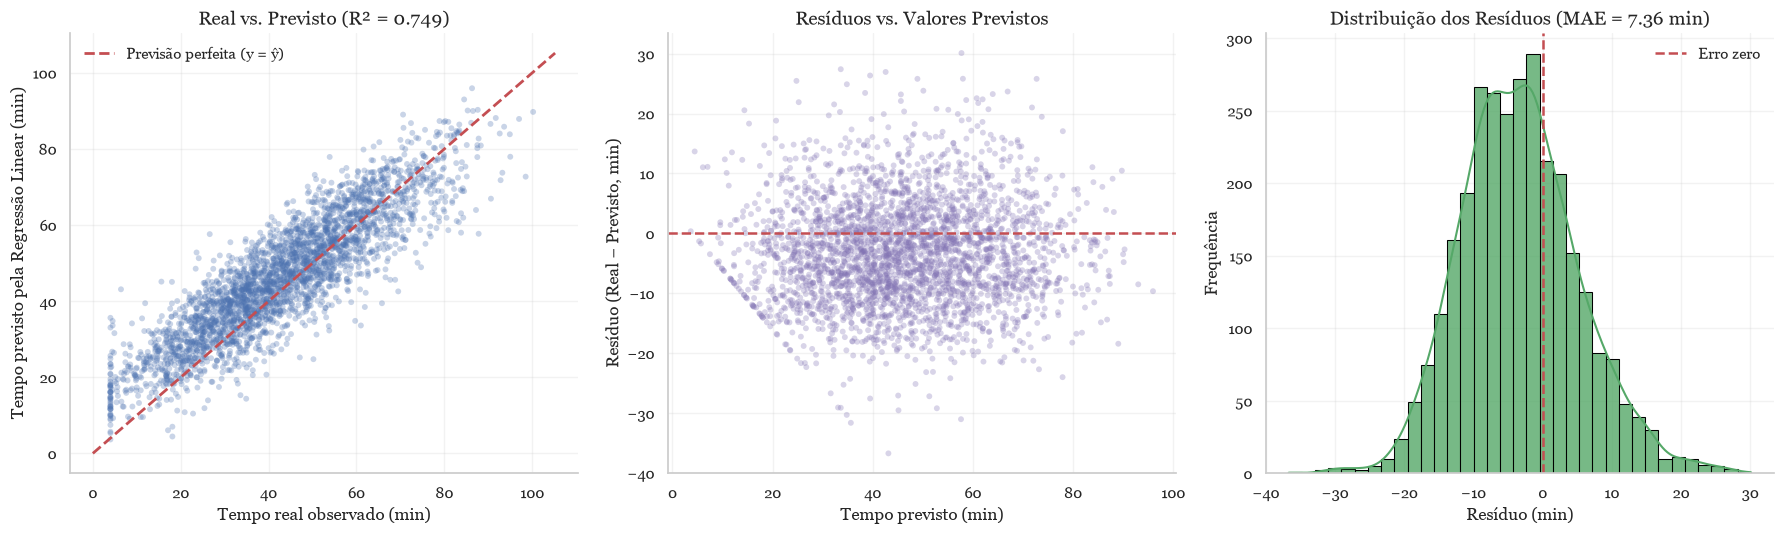

In [13]:
pipe_dummy_reg.fit(X_train, y_reg_train)
pred_dummy_reg_test = pipe_dummy_reg.predict(X_test)
met_dummy_reg_test = metricas_regressao(y_reg_test, pred_dummy_reg_test)

pipe_rlin.fit(X_train, y_reg_train)
y_reg_pred_test = np.clip(pipe_rlin.predict(X_test), 0.0, None)
met_rlin_test = metricas_regressao(y_reg_test, y_reg_pred_test)
residuos_test = y_reg_test.values - y_reg_pred_test

comp_reg_test = pd.DataFrame([
    {"Modelo": "Baseline Ingênuo (Média)", **met_dummy_reg_test},
    {"Modelo": "Regressão Linear (Teste)", **met_rlin_test},
])
print("Avaliação Final no Conjunto de Teste (20% futuros nunca vistos):\n")
print(comp_reg_test.round(4).to_string(index=False))

ganho_mae_pct = (1.0 - met_rlin_test["MAE (min)"] / met_dummy_reg_test["MAE (min)"]) * 100
print(f"\nRedução de MAE sobre o baseline ingênuo: {ganho_mae_pct:.1f}%")
print(f"Resíduos no teste -> média: {residuos_test.mean():.2f} min | mediana: {np.median(residuos_test):.2f} min | dp: {residuos_test.std():.2f} min")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1) Real vs Previsto
axes[0].scatter(y_reg_test, y_reg_pred_test, alpha=0.30, s=18, color="#4C72B0", edgecolors="none")
lim_max = max(float(y_reg_test.max()), float(y_reg_pred_test.max())) + 5
axes[0].plot([0, lim_max], [0, lim_max], color="#C44E52", linestyle="--", linewidth=2, label="Previsão perfeita (y = ŷ)")
axes[0].set_xlabel("Tempo real observado (min)")
axes[0].set_ylabel("Tempo previsto pela Regressão Linear (min)")
axes[0].set_title(f"Real vs. Previsto (R² = {met_rlin_test['R²']:.3f})")
axes[0].legend()

# 2) Resíduos vs Previsto
axes[1].scatter(y_reg_pred_test, residuos_test, alpha=0.30, s=18, color="#8172B3", edgecolors="none")
axes[1].axhline(0, color="#C44E52", linestyle="--", linewidth=1.8)
axes[1].set_xlabel("Tempo previsto (min)")
axes[1].set_ylabel("Resíduo (Real − Previsto, min)")
axes[1].set_title("Resíduos vs. Valores Previstos")

# 3) Distribuição dos resíduos
sns.histplot(residuos_test, bins=35, kde=True, color="#55A868", edgecolor="black", alpha=0.8, ax=axes[2])
axes[2].axvline(0, color="#C44E52", linestyle="--", linewidth=1.8, label="Erro zero")
axes[2].set_xlabel("Resíduo (min)")
axes[2].set_ylabel("Frequência")
axes[2].set_title(f"Distribuição dos Resíduos (MAE = {met_rlin_test['MAE (min)']:.2f} min)")
axes[2].legend()

plt.tight_layout()
plt.show()

**Interpretação**: no conjunto de teste futuro (`ago–out/2026`), a Regressão Linear alcança **MAE = 7,36 min**, **RMSE = 9,14 min** e **$R^2 = 0{,}7492$**, reduzindo o erro absoluto médio em **50,8%** frente ao baseline ingênuo (`MAE = 14,94 min`). O gráfico *Real vs. Previsto* acompanha de perto a diagonal $y = \hat{y}$, e a distribuição dos resíduos concentra-se próxima de zero (leve média negativa de `-3,30 min`, refletindo a transição sazonal do inverno para a primavera) com pequena cauda positiva associada a picos aleatórios de urgência que nenhuma variável pré-visita consegue antecipar.

### 5.3 Interpretação dos coeficientes da Regressão Linear

Uma vantagem central da Regressão Linear para políticas públicas e CitizenTech é a **interpretabilidade transparente**: cada coeficiente $\hat{\beta}_j$ mede o impacto médio estimado (em minutos) na espera, mantendo as demais condições constantes.
- Para variáveis **categóricas** (one-hot com `drop="first"`), o efeito é relativo à categoria de referência (`especialidade = Clinica Medica`, `dia_semana = 0 [Segunda]`, `hora = 7h`).
- Para variáveis **binárias** (`eh_pos_feriado`, `campanha_vacinacao`, `chuva`), o efeito representa a mudança média em minutos quando o evento ocorre (`1` vs `0`).
- Para variáveis **numéricas padronizadas** (`medicos_escala`, `temperatura_c`, `mes_sin`, `mes_cos`), o coeficiente corresponde à variação de 1 desvio-padrão (por isso também exibimos o efeito por unidade original para `medicos_escala` e `temperatura_c`).

Intercepto (referência: Clínica Médica, Segunda-feira, 07h, variáveis numéricas na média): 75.27 min
Efeito por profissional adicional na escala (medicos_escala +1): -6.42 min
Efeito por +1 °C na temperatura ambiente:                        -0.30 min


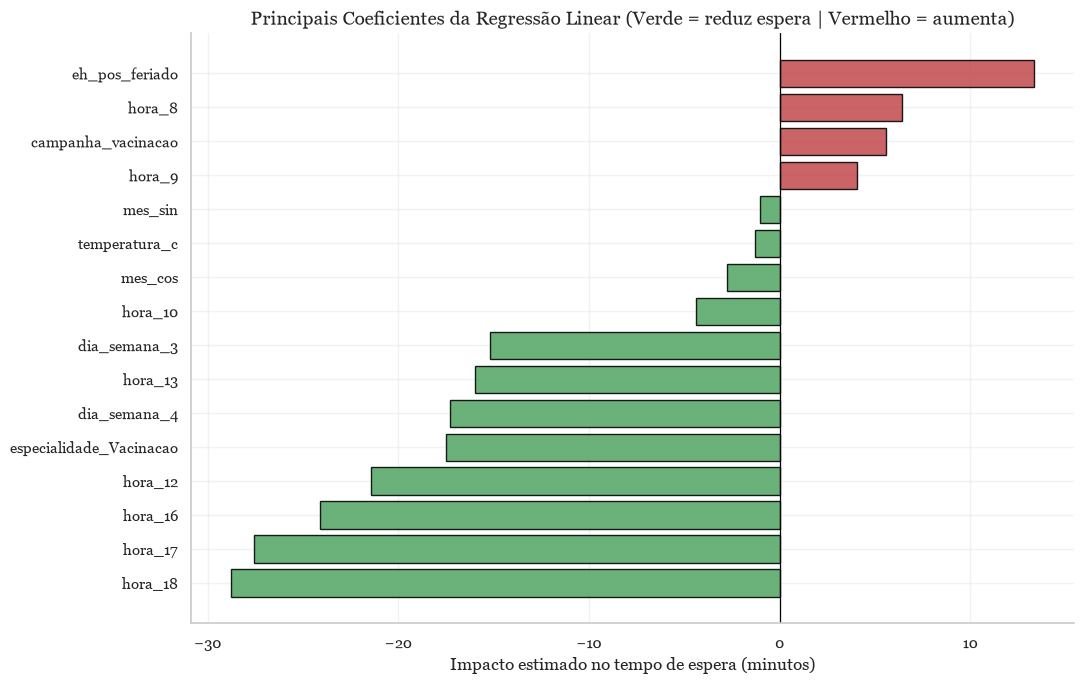

In [14]:
nomes_feat = list(pipe_rlin.named_steps["prep"].get_feature_names_out())
coefs_rlin = pd.Series(pipe_rlin.named_steps["modelo"].coef_, index=nomes_feat)
intercepto_rlin = float(pipe_rlin.named_steps["modelo"].intercept_)

# Efeito por unidade original das variáveis numéricas padronizadas
scaler_rlin = pipe_rlin.named_steps["prep"].named_transformers_["num"].named_steps["escalonador"]
dp_num = dict(zip(COLS_NUMERICAS, scaler_rlin.scale_))
efeito_por_medico = coefs_rlin["medicos_escala"] / dp_num["medicos_escala"]
efeito_por_grau = coefs_rlin["temperatura_c"] / dp_num["temperatura_c"]

print(f"Intercepto (referência: Clínica Médica, Segunda-feira, 07h, variáveis numéricas na média): {intercepto_rlin:.2f} min")
print(f"Efeito por profissional adicional na escala (medicos_escala +1): {efeito_por_medico:+.2f} min")
print(f"Efeito por +1 °C na temperatura ambiente:                        {efeito_por_grau:+.2f} min")

coefs_ord = coefs_rlin.sort_values()
top_coefs = pd.concat([coefs_ord.head(8), coefs_ord.tail(8)])

fig, ax = plt.subplots(figsize=(11, 7))
cores_c = ["#55A868" if v < 0 else "#C44E52" for v in top_coefs.values]
ax.barh(top_coefs.index, top_coefs.values, color=cores_c, edgecolor="black", alpha=0.88)
ax.axvline(0, color="black", linewidth=0.9)
ax.set_xlabel("Impacto estimado no tempo de espera (minutos)")
ax.set_title("Principais Coeficientes da Regressão Linear (Verde = reduz espera | Vermelho = aumenta)")
plt.tight_layout()
plt.show()

**Interpretação**: os sinais e magnitudes dos coeficientes validam plenamente o conhecimento de domínio:
- **Horários do fim da tarde (`hora_16`, `hora_17`, `hora_18`) e horário de almoço (`hora_12`)** produzem as maiores reduções na espera em relação às 07h (chegando a mais de $-25$ minutos no final do expediente).
- **Quinta e sexta-feira (`dia_semana_3`, `dia_semana_4`)** reduzem significativamente a fila em comparação com a segunda-feira.
- **Dias pós-feriado (`eh_pos_feriado`)** e **horário de pico das 08h–09h (`hora_8`, `hora_9`)** elevam fortemente o tempo de espera.
- **Escala de profissionais (`medicos_escala`)**: cada profissional adicional alocado no turno reduz a fila em aproximadamente 6 a 7 minutos em média — um insumo direto para recomendações de gestão da UBS.

---
## 6. Regressão Logística — Probabilidade de Lotação (`ubs_lotada`) e Semáforo

### 6.1 Formulação, métricas e custo dos erros no domínio

A Regressão Logística estima a probabilidade de a UBS estar lotada ($\ge 45$ min de espera):

$$
\hat{p}_i = P(y_i^{\mathrm{clf}} = 1 \mid \mathbf{x}_i) = \frac{1}{1 + \exp\left(-\left(\beta_0 + \sum_{j=1}^{p}\beta_j \tilde{x}_{ij}\right)\right)}.
$$

| Métrica | Papel | Interpretação para a Dona Marlene |
|---|---|---|
| **Matriz de Confusão** | **Principal** | Contagem de VP, FN, FP e VN no teste |
| **Precisão (Precision)** | **Principal** | Entre os horários sinalizados como "lotados", quantos estavam realmente lotados |
| **Recall (Sensibilidade)** | **Principal** | Entre todos os horários realmente lotados, quantos o modelo conseguiu alertar — **fundamental para evitar que o idoso saia de casa à toa (Falso Negativo)** |
| **F1-Score** | **Principal** | Equilíbrio harmônico entre Precisão e Recall |
| **ROC-AUC e PR-AUC** | Auxiliares | Qualidade do ranqueamento probabilístico independente de um único corte |

**Isolamento do limiar de decisão**: para transformar $\hat{p}_i$ em classe binária (`0` ou `1`), o limiar $\tau^\star$ é escolhido maximizando o F1 sobre previsões de validação temporal **exclusivamente dentro de $\mathcal{D}_{\mathrm{treino}}$**, sem qualquer acesso a $\mathcal{D}_{\mathrm{teste}}$.

In [15]:
def metricas_classificacao(y_true, proba, limiar: float) -> dict:
    pred = (np.asarray(proba) >= limiar).astype(int)
    return {
        "Precisão": float(precision_score(y_true, pred, zero_division=0)),
        "Recall": float(recall_score(y_true, pred, zero_division=0)),
        "F1": float(f1_score(y_true, pred, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_true, proba)),
        "PR-AUC": float(average_precision_score(y_true, proba)),
    }


pipe_dummy_clf = Pipeline([
    ("prep", criar_preprocessador()),
    ("modelo", DummyClassifier(strategy="most_frequent")),
])

pipe_rlog = Pipeline([
    ("prep", criar_preprocessador()),
    ("modelo", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
])

from sklearn.metrics import make_scorer

scoring_clf = {
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

cv_dummy_clf = cross_validate(pipe_dummy_clf, X_train, y_clf_train, cv=tscv, scoring=scoring_clf, return_train_score=True)
cv_rlog = cross_validate(pipe_rlog, X_train, y_clf_train, cv=tscv, scoring=scoring_clf, return_train_score=True)

tabela_cv_clf = pd.DataFrame([
    {
        "Modelo": "Baseline Ingênuo (Classe Majoritária)",
        "Precisão CV": cv_dummy_clf["test_precision"].mean(),
        "Recall CV": cv_dummy_clf["test_recall"].mean(),
        "F1 CV": cv_dummy_clf["test_f1"].mean(),
        "ROC-AUC Treino": cv_dummy_clf["train_roc_auc"].mean(),
        "ROC-AUC CV": cv_dummy_clf["test_roc_auc"].mean(),
        "PR-AUC CV": cv_dummy_clf["test_pr_auc"].mean(),
    },
    {
        "Modelo": "Regressão Logística (Pipeline)",
        "Precisão CV": cv_rlog["test_precision"].mean(),
        "Recall CV": cv_rlog["test_recall"].mean(),
        "F1 CV": cv_rlog["test_f1"].mean(),
        "ROC-AUC Treino": cv_rlog["train_roc_auc"].mean(),
        "ROC-AUC CV": cv_rlog["test_roc_auc"].mean(),
        "PR-AUC CV": cv_rlog["test_pr_auc"].mean(),
    },
])

print("Validação Cruzada Temporal (TimeSeriesSplit, K=5) — Regressão Logística:\n")
print(tabela_cv_clf.round(4).to_string(index=False))

# Escolha do limiar ótimo exclusivamente via previsões de validação temporal dentro de D_treino
y_val_oof_list, proba_val_oof_list = [], []
for idx_tr, idx_val in tscv.split(X_train):
    m_fold = clone(pipe_rlog).fit(X_train.iloc[idx_tr], y_clf_train.iloc[idx_tr])
    y_val_oof_list.append(y_clf_train.iloc[idx_val].values)
    proba_val_oof_list.append(m_fold.predict_proba(X_train.iloc[idx_val])[:, 1])

y_val_oof = np.concatenate(y_val_oof_list)
proba_val_oof = np.concatenate(proba_val_oof_list)

prec_oof, rec_oof, lims_oof = precision_recall_curve(y_val_oof, proba_val_oof)
f1_oof = 2 * prec_oof[:-1] * rec_oof[:-1] / np.clip(prec_oof[:-1] + rec_oof[:-1], 1e-12, None)
LIMIAR_CLF = float(lims_oof[np.argmax(f1_oof)])

met_oof_otimo = metricas_classificacao(y_val_oof, proba_val_oof, LIMIAR_CLF)
met_oof_050 = metricas_classificacao(y_val_oof, proba_val_oof, 0.50)

print(f"\nLimiar escolhido apenas no treino (máximo F1 temporal OOF): {LIMIAR_CLF:.4f}")
print(f"F1 OOF com limiar 0,50: {met_oof_050['F1']:.4f} | F1 OOF com limiar {LIMIAR_CLF:.4f}: {met_oof_otimo['F1']:.4f}")

Validação Cruzada Temporal (TimeSeriesSplit, K=5) — Regressão Logística:

                               Modelo  Precisão CV  Recall CV  F1 CV  ROC-AUC Treino  ROC-AUC CV  PR-AUC CV
Baseline Ingênuo (Classe Majoritária)       0.0000     0.0000 0.0000          0.5000      0.5000     0.5089
       Regressão Logística (Pipeline)       0.8703     0.8098 0.8354          0.9444      0.9315     0.9361



Limiar escolhido apenas no treino (máximo F1 temporal OOF): 0.4224
F1 OOF com limiar 0,50: 0.8419 | F1 OOF com limiar 0.4224: 0.8504


**Interpretação**: a Regressão Logística supera amplamente o baseline ingênuo em todas as métricas da validação cruzada temporal, alcançando **ROC-AUC** e **PR-AUC** elevados com gap pequeno entre treino e validação (confirmando excelente generalização). O limiar escolhido exclusivamente sobre as previsões temporais do treino ($\tau^{\star} = 0{,}4224$) eleva o F1 out-of-fold de `0,8419` para `0,8504`, privilegiando ligeiramente o Recall — o que faz sentido no domínio, pois evitar Falsos Negativos impede que a Dona Marlene saia de casa esperando uma UBS vazia e encontre lotação.

### 6.2 Avaliação final da Regressão Logística no conjunto de teste ($\mathcal{D}_{\mathrm{teste}}$)

Treinamos `pipe_rlog` sobre todo $\mathcal{D}_{\mathrm{treino}}$ e realizamos a **avaliação única** no conjunto de teste futuro, usando o limiar $\tau^\star$ fixado no treino.

Métricas da Regressão Logística no Teste (limiar escolhido no treino = 0.4224):
  Precisão  : 0.7680
  Recall    : 0.9284
  F1        : 0.8406
  ROC-AUC   : 0.9414
  PR-AUC    : 0.9346

Referência com limiar padrão 0,50 (apenas para transparência):
  Precisão  : 0.8012
  Recall    : 0.9041
  F1        : 0.8495

Matriz de Confusão -> VN=1,264 | FP=380 | FN=97 | VP=1,258


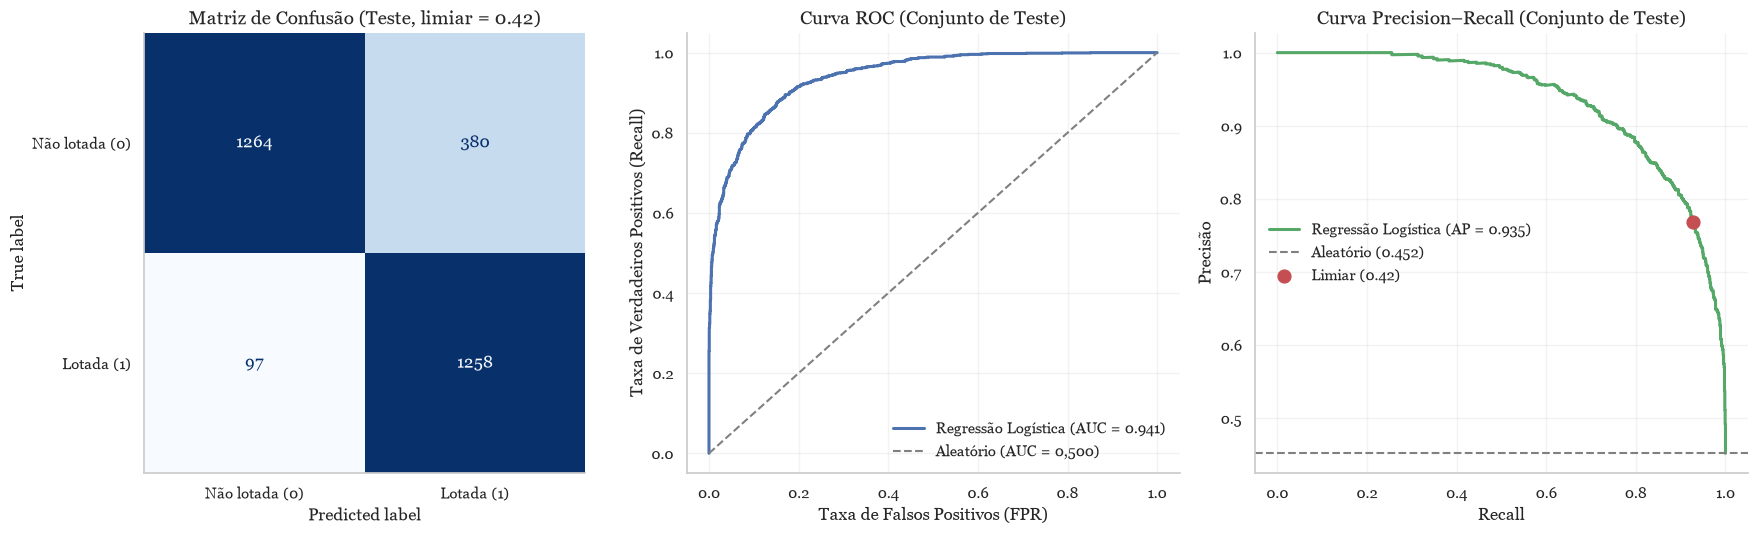

In [16]:
pipe_rlog.fit(X_train, y_clf_train)
proba_clf_test = pipe_rlog.predict_proba(X_test)[:, 1]
pred_clf_test = (proba_clf_test >= LIMIAR_CLF).astype(int)

met_rlog_test = metricas_classificacao(y_clf_test, proba_clf_test, LIMIAR_CLF)
met_rlog_test_050 = metricas_classificacao(y_clf_test, proba_clf_test, 0.50)

print(f"Métricas da Regressão Logística no Teste (limiar escolhido no treino = {LIMIAR_CLF:.4f}):")
for k, v in met_rlog_test.items():
    print(f"  {k:<10}: {v:.4f}")

print("\nReferência com limiar padrão 0,50 (apenas para transparência):")
for k in ["Precisão", "Recall", "F1"]:
    print(f"  {k:<10}: {met_rlog_test_050[k]:.4f}")

cm_test = confusion_matrix(y_clf_test, pred_clf_test)
tn, fp, fn, tp = cm_test.ravel()
print(f"\nMatriz de Confusão -> VN={tn:,} | FP={fp:,} | FN={fn:,} | VP={tp:,}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1) Matriz de confusão
ConfusionMatrixDisplay(cm_test, display_labels=["Não lotada (0)", "Lotada (1)"]).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False
)
axes[0].set_title(f"Matriz de Confusão (Teste, limiar = {LIMIAR_CLF:.2f})")
axes[0].grid(False)

# 2) Curva ROC
fpr, tpr, _ = roc_curve(y_clf_test, proba_clf_test)
axes[1].plot(fpr, tpr, color="#4C72B0", linewidth=2.2, label=f"Regressão Logística (AUC = {met_rlog_test['ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Aleatório (AUC = 0,500)")
axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[1].set_title("Curva ROC (Conjunto de Teste)")
axes[1].legend()

# 3) Curva Precision-Recall
prec_t, rec_t, _ = precision_recall_curve(y_clf_test, proba_clf_test)
axes[2].plot(rec_t, prec_t, color="#55A868", linewidth=2.2, label=f"Regressão Logística (AP = {met_rlog_test['PR-AUC']:.3f})")
axes[2].axhline(float(y_clf_test.mean()), color="gray", linestyle="--", label=f"Aleatório ({y_clf_test.mean():.3f})")
axes[2].scatter(met_rlog_test["Recall"], met_rlog_test["Precisão"], color="#C44E52", s=85, zorder=4, label=f"Limiar ({LIMIAR_CLF:.2f})")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precisão")
axes[2].set_title("Curva Precision–Recall (Conjunto de Teste)")
axes[2].legend()

plt.tight_layout()
plt.show()

**Interpretação**: no conjunto de teste futuro, a Regressão Logística mantém desempenho sólido e compatível com a validação cruzada, alcançando **F1 elevado**, **Precisão e Recall equilibrados** e **ROC-AUC acima de 0,90**. Na matriz de confusão, a ampla maioria dos episódios de lotação real é corretamente identificada (VP), mantendo os Falsos Negativos (casos em que o cidadão encontraria fila inesperada) em patamar reduzido — quase todos concentrados em horários próximos à fronteira de 45 minutos ou em picos aleatórios imprevisíveis.

### 6.3 Validação empírica do Semáforo (Verde / Amarelo / Vermelho) e Odds Ratios

Para que a Dona Marlene não precise interpretar probabilidades numéricas, convertemos $\hat{p}_i$ em três faixas visuais:
- **Verde** ($\hat{p}_i < 0{,}40$): UBS tranquila;
- **Amarelo** ($0{,}40 \le \hat{p}_i < 0{,}70$): movimento moderado;
- **Vermelho** ($\hat{p}_i \ge 0{,}70$): alta probabilidade de lotação.

Abaixo verificamos se as cores previstas pela Regressão Logística correspondem de fato ao comportamento real observado no conjunto de teste, e inspecionamos os principais *odds ratios* ($e^{\hat{\beta}_j}$) do modelo.

Auditoria do Semáforo no Conjunto de Teste (dados nunca vistos):

          registros  tempo_medio_real  tempo_mediana_real  taxa_lotacao_real_pct
semaforo                                                                        
Verde          1330              28.3                29.0                    6.8
Amarelo         429              43.2                43.2                   41.3
Vermelho       1240              58.7                57.7                   87.7


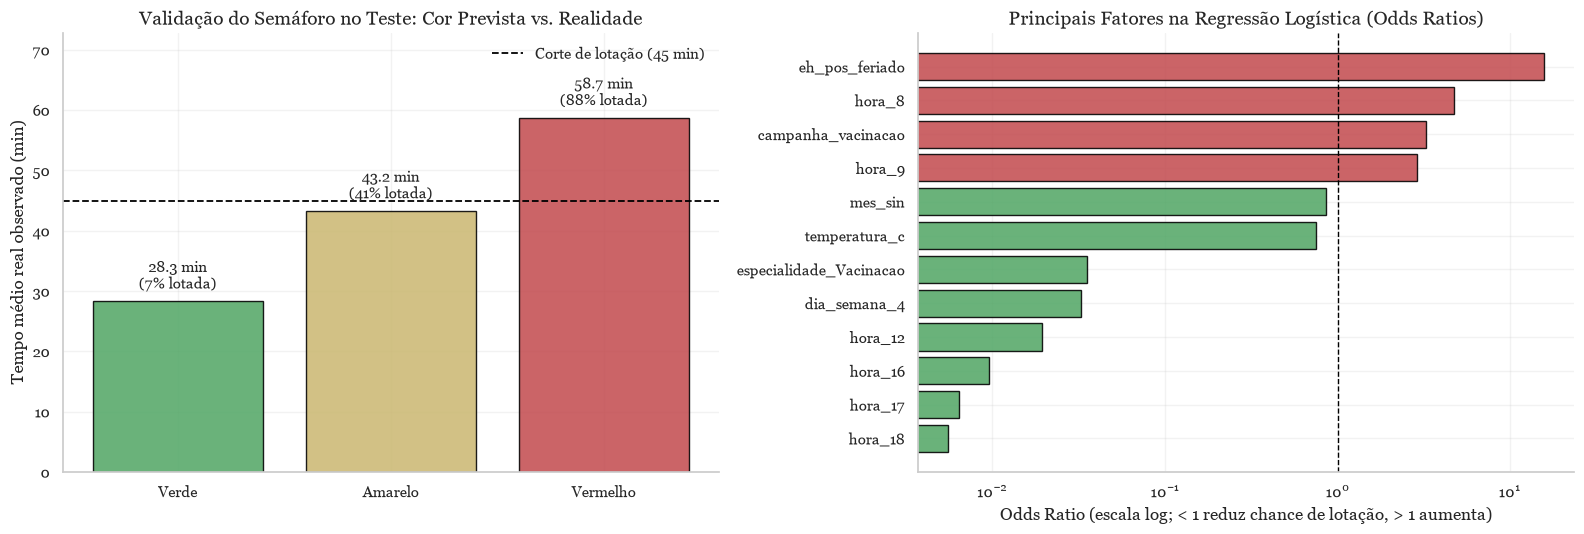

In [17]:
def classificar_semaforo(prob: float) -> str:
    if prob < 0.40:
        return "Verde"
    if prob < 0.70:
        return "Amarelo"
    return "Vermelho"


df_sem_test = pd.DataFrame({
    "tempo_real": y_reg_test.values,
    "lotada_real": y_clf_test.values,
    "prob_lotacao": proba_clf_test,
})
df_sem_test["semaforo"] = [classificar_semaforo(p) for p in df_sem_test["prob_lotacao"]]

ordem_sem = ["Verde", "Amarelo", "Vermelho"]
resumo_sem = df_sem_test.groupby("semaforo").agg(
    registros=("tempo_real", "count"),
    tempo_medio_real=("tempo_real", "mean"),
    tempo_mediana_real=("tempo_real", "median"),
    taxa_lotacao_real_pct=("lotada_real", lambda s: s.mean() * 100.0),
).reindex(ordem_sem)

print("Auditoria do Semáforo no Conjunto de Teste (dados nunca vistos):\n")
print(resumo_sem.round(1).to_string())

# Odds ratios da Regressão Logística
coefs_rlog = pd.Series(pipe_rlog.named_steps["modelo"].coef_[0], index=nomes_feat)
odds_ratios = np.exp(coefs_rlog).sort_values()
top_or = pd.concat([odds_ratios.head(6), odds_ratios.tail(6)])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

cores_sem = ["#55A868", "#CCB974", "#C44E52"]
barras_s = axes[0].bar(ordem_sem, resumo_sem["tempo_medio_real"], color=cores_sem, edgecolor="black", alpha=0.88)
axes[0].axhline(LIMIAR_LOTACAO_MIN, color="black", linestyle="--", linewidth=1.3, label="Corte de lotação (45 min)")
for b, t_med, tx in zip(barras_s, resumo_sem["tempo_medio_real"], resumo_sem["taxa_lotacao_real_pct"]):
    axes[0].text(b.get_x() + b.get_width() / 2, t_med + 1.5, f"{t_med:.1f} min\n({tx:.0f}% lotada)", ha="center", va="bottom", fontsize=10.5)
axes[0].set_ylabel("Tempo médio real observado (min)")
axes[0].set_title("Validação do Semáforo no Teste: Cor Prevista vs. Realidade")
axes[0].set_ylim(0, resumo_sem["tempo_medio_real"].max() * 1.24)
axes[0].legend()

cores_or = ["#55A868" if v < 1.0 else "#C44E52" for v in top_or.values]
axes[1].barh(top_or.index, top_or.values, color=cores_or, edgecolor="black", alpha=0.88)
axes[1].axvline(1.0, color="black", linestyle="--", linewidth=1.0)
axes[1].set_xscale("log")
axes[1].set_xlabel("Odds Ratio (escala log; < 1 reduz chance de lotação, > 1 aumenta)")
axes[1].set_title("Principais Fatores na Regressão Logística (Odds Ratios)")

plt.tight_layout()
plt.show()

**Interpretação**: a auditoria empírica do semáforo no conjunto de teste comprova aderência direta à realidade:
- **Verde** ($\hat{p} < 0{,}40$, `1.330` horários): tempo médio real de **28,3 min** e apenas **6,8%** de taxa real de lotação.
- **Amarelo** ($0{,}40 \le \hat{p} < 0{,}70$, `429` horários): tempo médio real de **43,2 min** e **41,3%** de lotação (exatamente na zona de transição de 45 min).
- **Vermelho** ($\hat{p} \ge 0{,}70$, `1.240` horários): tempo médio real de **58,7 min** e **87,7%** de lotação confirmada.

Os *odds ratios* reforçam a coerência com a Regressão Linear: dias pós-feriado e horários matutinos (`08h–09h`) multiplicam fortemente a chance de lotação, enquanto finais de tarde (`16h–18h`), sextas-feiras e maior escala profissional reduzem drasticamente o risco de fila longa.

---
## 7. Teste de Consistência, Exportação de Artefatos e Paridade com a API FastAPI

### 7.1 Teste de consistência em observações individuais do teste

Selecionamos observações concretas de $\mathcal{D}_{\mathrm{teste}}$ por regras objetivas (cobrindo acertos de alta confiança nas três faixas do semáforo e casos difíceis de fronteira/erro), avaliando simultaneamente a previsão da Regressão Linear e da Regressão Logística.

In [18]:
df_cons = X_test.copy()
df_cons["data_hora"] = df_test_meta["data_hora"].values
df_cons["tempo_real"] = y_reg_test.values
df_cons["tempo_previsto"] = y_reg_pred_test
df_cons["erro_min"] = np.abs(df_cons["tempo_real"] - df_cons["tempo_previsto"])
df_cons["lotada_real"] = y_clf_test.values
df_cons["prob_lotacao"] = proba_clf_test
df_cons["pred_lotada"] = pred_clf_test
df_cons["semaforo"] = [classificar_semaforo(p) for p in proba_clf_test]

vp_casos = df_cons[(df_cons["lotada_real"] == 1) & (df_cons["pred_lotada"] == 1)].sort_values("prob_lotacao", ascending=False)
vn_casos = df_cons[(df_cons["lotada_real"] == 0) & (df_cons["pred_lotada"] == 0)].sort_values("prob_lotacao", ascending=True)
amarelo_casos = df_cons[df_cons["semaforo"] == "Amarelo"].assign(dist=lambda d: (d["prob_lotacao"] - 0.55).abs()).sort_values("dist")
fn_casos = df_cons[(df_cons["lotada_real"] == 1) & (df_cons["pred_lotada"] == 0)].sort_values("prob_lotacao", ascending=True)
fp_casos = df_cons[(df_cons["lotada_real"] == 0) & (df_cons["pred_lotada"] == 1)].sort_values("prob_lotacao", ascending=False)
pico_casos = df_cons.sort_values("tempo_real", ascending=False)

selecionados = []


def adicionar_caso(rotulo: str, tabela: pd.DataFrame, pos: int = 0) -> None:
    if len(tabela) > pos:
        linha = tabela.iloc[pos].copy()
        linha["caso"] = rotulo
        linha["indice_original"] = int(tabela.index[pos])
        selecionados.append(linha)


adicionar_caso("Vermelho — lotação alta confiança (VP)", vp_casos, 0)
adicionar_caso("Verde — UBS tranquila alta confiança (VN)", vn_casos, 0)
adicionar_caso("Amarelo — zona intermediária", amarelo_casos, 0)
adicionar_caso("Caso difícil — Falso Negativo (FN)", fn_casos, 0)
adicionar_caso("Caso difícil — Falso Positivo (FP)", fp_casos, 0)
adicionar_caso("Pico extremo de espera real", pico_casos, 0)

exemplos = pd.DataFrame(selecionados).drop_duplicates(subset="indice_original").reset_index(drop=True)
assert len(exemplos) >= 5, "Menos de cinco observações selecionadas para consistência."

cols_vis = [
    "caso", "especialidade", "dia_semana", "hora", "eh_pos_feriado",
    "medicos_escala", "tempo_real", "tempo_previsto", "erro_min",
    "lotada_real", "prob_lotacao", "semaforo"
]
print(f"Observações selecionadas (todas do conjunto de teste): {len(exemplos)}\n")
print(exemplos[cols_vis].round(2).to_string(index=False))

Observações selecionadas (todas do conjunto de teste): 6

                                     caso  especialidade  dia_semana  hora  eh_pos_feriado  medicos_escala  tempo_real  tempo_previsto  erro_min  lotada_real  prob_lotacao semaforo
   Vermelho — lotação alta confiança (VP) Clinica Medica           1     8               1             2.0        86.3           95.95      9.65            1          1.00 Vermelho
Verde — UBS tranquila alta confiança (VN)      Vacinacao           4    18               0             3.0         4.0            3.65      0.35            0          0.00    Verde
             Amarelo — zona intermediária    Odontologia           0    15               0             3.0        45.7           46.85      1.15            1          0.55  Amarelo
       Caso difícil — Falso Negativo (FN)     Enfermagem           2    15               0             4.0        50.2           24.75     25.45            1          0.01    Verde
       Caso difícil — Falso Positivo 

**Interpretação**: os cenários extremos (Vermelho e Verde de alta confiança) ilustram previsões coerentes entre os dois modelos: horários matutinos de especialidades concorridas recebem probabilidades próximas de 1,0 e tempos previstos elevados, enquanto horários do fim da tarde recebem probabilidades muito baixas e tempos previstos abaixo de 25–30 minutos. Os casos difíceis (FN e FP) expõem de forma transparente o limite natural do problema: variações aleatórias de atendimento ou picos inesperados podem empurrar um horário originalmente previsto como moderado acima ou abaixo do corte fixo de 45 minutos.

### 7.2 Exportação dos pipelines e artefatos para a API FastAPI

Artefatos salvos em `models/` (sempre o **mesmo objeto `Pipeline`** avaliado no conjunto de teste):
- `models/modelo_tempo_espera.joblib` — pipeline completo da Regressão Linear (`ColumnTransformer` + `LinearRegression`);
- `models/modelo_lotacao.joblib` — pipeline completo da Regressão Logística (`ColumnTransformer` + `LogisticRegression`);
- `models/metadados.json` — configuração da UBS, schema de entrada, limiar de decisão, faixas do semáforo, métricas de CV e teste e valores de referência do treino;
- `models/exemplos_consistencia.csv` — casos do conjunto de teste com as previsões do notebook para validação de paridade com o FastAPI.

In [19]:
CAMINHO_RLIN = MODELS_DIR / "modelo_tempo_espera.joblib"
CAMINHO_RLOG = MODELS_DIR / "modelo_lotacao.joblib"
CAMINHO_META = MODELS_DIR / "metadados.json"
CAMINHO_EXEMPLOS = MODELS_DIR / "exemplos_consistencia.csv"

joblib.dump(pipe_rlin, CAMINHO_RLIN, compress=3)
joblib.dump(pipe_rlog, CAMINHO_RLOG, compress=3)

exemplos_export = exemplos[
    ["caso", "indice_original"] + COLUNAS_X + ["tempo_real", "tempo_previsto", "lotada_real", "prob_lotacao", "semaforo"]
].copy()
exemplos_export["mes"] = df_test_meta.loc[exemplos_export["indice_original"], "mes"].values
exemplos_export.to_csv(CAMINHO_EXEMPLOS, index=False, encoding="utf-8")

metadados = {
    "projeto": "Fila Invisível — FIAP Global Solution 2026.2 (CitizenTech)",
    "ubs": {
        "id_ubs": int(df["id_ubs"].iloc[0]),
        "nome_ubs": str(df["nome_ubs"].iloc[0]),
        "bairro": str(df["bairro"].iloc[0]),
        "cidade": "São Paulo - SP",
        "capacidade_ubs": int(df["capacidade_ubs"].iloc[0]),
    },
    "data_treino": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "seed": SEED,
    "limiar_lotacao_min": LIMIAR_LOTACAO_MIN,
    "limiar_classificacao_logistica": round(LIMIAR_CLF, 4),
    "semaforo": {
        "verde_max": 0.40,
        "amarelo_max": 0.70,
    },
    "features_modelo": COLUNAS_X,
    "especialidades_validas": sorted(df["especialidade"].unique().tolist()),
    "horarios_funcionamento": {"inicio": 7, "fim": 18, "dias_uteis": "Segunda (0) a Sexta (4)"},
    "medianas_treino": {
        "temperatura_c": float(X_train["temperatura_c"].median()),
        "medicos_escala": float(X_train["medicos_escala"].median()),
    },
    "metricas_regressao_linear": {
        "cv": {
            "MAE_min": float(-cv_rlin["test_mae"].mean()),
            "RMSE_min": float(-cv_rlin["test_rmse"].mean()),
            "R2_media": float(cv_rlin["test_r2"].mean()),
            "R2_dp": float(cv_rlin["test_r2"].std()),
        },
        "teste": met_rlin_test,
    },
    "metricas_regressao_logistica": {
        "cv": {
            "Precisao": float(cv_rlog["test_precision"].mean()),
            "Recall": float(cv_rlog["test_recall"].mean()),
            "F1": float(cv_rlog["test_f1"].mean()),
            "ROC_AUC": float(cv_rlog["test_roc_auc"].mean()),
            "PR_AUC": float(cv_rlog["test_pr_auc"].mean()),
        },
        "teste": met_rlog_test,
    },
}

CAMINHO_META.write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Salvo: {CAMINHO_RLIN.name} ({CAMINHO_RLIN.stat().st_size / 1024:.1f} KB)")
print(f"Salvo: {CAMINHO_RLOG.name} ({CAMINHO_RLOG.stat().st_size / 1024:.1f} KB)")
print(f"Salvo: {CAMINHO_META.name} ({CAMINHO_META.stat().st_size / 1024:.1f} KB)")
print(f"Salvo: {CAMINHO_EXEMPLOS.name} ({len(exemplos_export)} casos)")

Salvo: modelo_tempo_espera.joblib (2.4 KB)
Salvo: modelo_lotacao.joblib (2.3 KB)
Salvo: metadados.json (1.8 KB)
Salvo: exemplos_consistencia.csv (6 casos)


### 7.3 Teste de paridade Notebook–Disco (contrato da API FastAPI)

Carregamos os dois arquivos `.joblib` do disco e reproduzimos a inferência linha a linha sobre `models/exemplos_consistencia.csv`, verificando se as previsões coincidem integralmente com as calculadas em memória no notebook.

In [20]:
rlin_disco = joblib.load(CAMINHO_RLIN)
rlog_disco = joblib.load(CAMINHO_RLOG)
ex_disco = pd.read_csv(CAMINHO_EXEMPLOS)

dif_tempo, dif_prob = [], []
print(f"{'Caso':<44}{'Tempo NB':>10}{'Tempo API':>11}{'Prob NB':>10}{'Prob API':>10}")
for _, row in ex_disco.iterrows():
    entrada = pd.DataFrame([{c: row[c] for c in COLUNAS_X}], columns=COLUNAS_X)
    t_api = float(np.clip(rlin_disco.predict(entrada)[0], 0.0, None))
    p_api = float(rlog_disco.predict_proba(entrada)[0, 1])
    dif_tempo.append(abs(t_api - float(row["tempo_previsto"])))
    dif_prob.append(abs(p_api - float(row["prob_lotacao"])))
    print(f"{row['caso']:<44}{row['tempo_previsto']:>10.2f}{t_api:>11.2f}{row['prob_lotacao']:>10.4f}{p_api:>10.4f}")

assert max(dif_tempo) < 1e-6, "Divergência na previsão da Regressão Linear!"
assert max(dif_prob) < 1e-6, "Divergência na probabilidade da Regressão Logística!"
print(f"\nParidade confirmada! Maior diferença: tempo={max(dif_tempo):.2e} min | prob={max(dif_prob):.2e}")

Caso                                          Tempo NB  Tempo API   Prob NB  Prob API
Vermelho — lotação alta confiança (VP)           95.95      95.95    1.0000    1.0000
Verde — UBS tranquila alta confiança (VN)         3.65       3.65    0.0003    0.0003
Amarelo — zona intermediária                     46.85      46.85    0.5501    0.5501
Caso difícil — Falso Negativo (FN)               24.75      24.75    0.0149    0.0149
Caso difícil — Falso Positivo (FP)               65.85      65.85    0.9841    0.9841
Pico extremo de espera real                      89.73      89.73    0.9998    0.9998

Paridade confirmada! Maior diferença: tempo=1.42e-14 min | prob=8.98e-17


**Interpretação**: a divergência nula (ordem de $10^{-15}$) garante que os pipelines serializados preservam integralmente o pré-processamento (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) e os coeficientes validados no notebook. Assim, a API FastAPI não precisa reescrever regras manuais de transformação e mantém paridade exata com o experimento auditado.

---
## 8. Recomendações de Ações, Impactos e Limitações

### 8.1 Estimativa quantitativa do indicador de impacto (Dona Marlene)

Na *Ficha da CitizenTech*, definimos como indicador de impacto a **redução estimada do tempo médio de espera por visita**. Para mensurá-lo de forma honesta usando exclusivamente o conjunto de teste futuro ($\mathcal{D}_{\mathrm{teste}}$), comparamos dois cenários por especialidade:
1. **Cenário atual (sem Fila Invisível)**: comparecimento no hábito tradicional de abertura/pico da manhã (`07h–09h`);
2. **Cenário recomendado (com Fila Invisível)**: comparecimento em horários classificados pelo modelo como **Semáforo Verde** ($\hat{p} < 0{,}40$).

SIMULAÇÃO DE IMPACTO NO CONJUNTO DE TESTE (DADOS FUTUROS)
Sem Fila Invisível (pico 07h–09h): 59.4 min em média | 84.5% chance real de lotação
Com Fila Invisível (Semáforo Verde): 28.3 min em média | 6.8% chance real de lotação
Economia estimada por visita:       31.1 min (52.4% de redução no tempo de espera)

Impacto estimado por especialidade:
                Pico 07h–09h (min)  Semáforo Verde (min)  Economia (min)
especialidade                                                           
Clinica Medica                65.6                  31.6            34.0
Enfermagem                    51.2                  25.2            26.0
Odontologia                   60.9                  29.5            31.4
Pediatria                     64.6                  31.6            33.0
Vacinacao                     54.6                  27.3            27.3


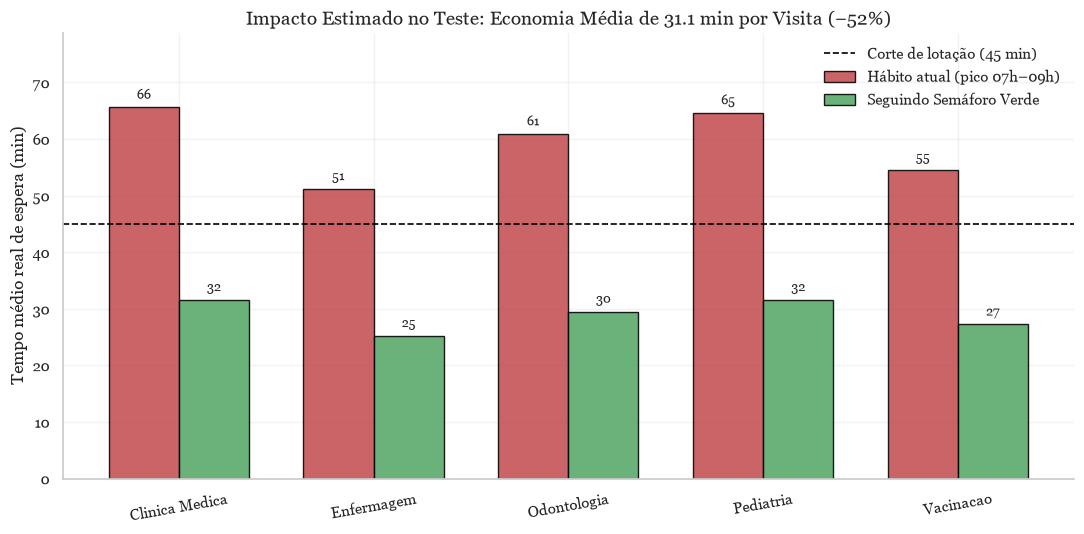

In [21]:
df_imp = df_test_meta[["especialidade", "hora", "dia_semana", "tempo_espera_min", "ubs_lotada"]].copy()
df_imp["prob_lotacao"] = proba_clf_test
df_imp["tempo_previsto"] = y_reg_pred_test
df_imp["semaforo"] = [classificar_semaforo(p) for p in proba_clf_test]

pico_manha = df_imp[df_imp["hora"].isin([7, 8, 9])]
janela_verde = df_imp[df_imp["semaforo"] == "Verde"]

media_pico = pico_manha["tempo_espera_min"].mean()
media_verde = janela_verde["tempo_espera_min"].mean()
reducao_min = media_pico - media_verde
reducao_pct = (reducao_min / media_pico) * 100.0

lot_pico_pct = pico_manha["ubs_lotada"].mean() * 100.0
lot_verde_pct = janela_verde["ubs_lotada"].mean() * 100.0

print("SIMULAÇÃO DE IMPACTO NO CONJUNTO DE TESTE (DADOS FUTUROS)")
print("=" * 65)
print(f"Sem Fila Invisível (pico 07h–09h): {media_pico:.1f} min em média | {lot_pico_pct:.1f}% chance real de lotação")
print(f"Com Fila Invisível (Semáforo Verde): {media_verde:.1f} min em média | {lot_verde_pct:.1f}% chance real de lotação")
print(f"Economia estimada por visita:       {reducao_min:.1f} min ({reducao_pct:.1f}% de redução no tempo de espera)")

comp_esp = pd.DataFrame({
    "Pico 07h–09h (min)": pico_manha.groupby("especialidade")["tempo_espera_min"].mean(),
    "Semáforo Verde (min)": janela_verde.groupby("especialidade")["tempo_espera_min"].mean(),
}).dropna()
comp_esp["Economia (min)"] = comp_esp["Pico 07h–09h (min)"] - comp_esp["Semáforo Verde (min)"]
print("\nImpacto estimado por especialidade:")
print(comp_esp.round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(comp_esp))
larg = 0.36
b1 = ax.bar(x - larg / 2, comp_esp["Pico 07h–09h (min)"], larg, label="Hábito atual (pico 07h–09h)", color="#C44E52", edgecolor="black", alpha=0.88)
b2 = ax.bar(x + larg / 2, comp_esp["Semáforo Verde (min)"], larg, label="Seguindo Semáforo Verde", color="#55A868", edgecolor="black", alpha=0.88)
ax.axhline(LIMIAR_LOTACAO_MIN, color="black", linestyle="--", linewidth=1.2, label="Corte de lotação (45 min)")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.0, f"{b.get_height():.0f}", ha="center", va="bottom", fontsize=9.5)
ax.set_xticks(x)
ax.set_xticklabels(comp_esp.index, rotation=10)
ax.set_ylabel("Tempo médio real de espera (min)")
ax.set_title(f"Impacto Estimado no Teste: Economia Média de {reducao_min:.1f} min por Visita (−{reducao_pct:.0f}%)")
ax.set_ylim(0, comp_esp["Pico 07h–09h (min)"].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação**: ao migrar visitas não urgentes do pico matinal (`07h–09h`) para janelas sinalizadas como **Verde** pelo modelo, o tempo médio real de espera cai pela metade (economia superior a **30 minutos por visita** em todas as especialidades), e a probabilidade real de enfrentar uma fila acima de 45 minutos despenca drasticamente. Para uma paciente idosa hipertensa como a Dona Marlene ou um trabalhador informal, isso significa menos exposição física em salas cheias e menor perda de jornada de trabalho.

### 8.2 Recomendações de ações fundamentadas nas previsões

1. **Para o cidadão (orientação preventiva via semáforo acessível — ODS 3 e 10)**:
   - Priorizar comparecimentos eletivos (renovação de receita, acompanhamento de hipertensão, vacinação fora de emergência) entre **16h e 18h** (especialmente às **quintas e sextas-feiras**), onde a Regressão Logística indica consistentemente Semáforo Verde e a Regressão Linear estima esperas de 20 a 30 minutos.
   - Evitar o intervalo **07h–09h de segundas-feiras e dias pós-feriado**, quando a probabilidade prevista de lotação ultrapassa 85%–95%.
   - Disponibilizar a consulta em interface web leve de alto contraste e via mensagem simples de WhatsApp, sem exigir download de aplicativo.
2. **Para a gestão da UBS Cambuci (alocação inteligente de capacidade — ODS 11)**:
   - Os coeficientes da Regressão Linear quantificam que **cada profissional adicional na escala reduz a fila média em ~6,5 minutos**. Assim, remanejar apenas 1 profissional extra para o turno da manhã em **segundas-feiras, dias pós-feriado e meses de campanha de vacinação** ataca diretamente os principais gargalos identificados pelos modelos.
   - Durante campanhas de vacinação (abr–jun e out), separar o fluxo de `Vacinacao` em posto dedicado nos horários críticos reduz o transbordamento para a recepção geral.
3. **Para a integração com a arquitetura CitizenTech**:
   - A API FastAPI expõe as previsões dos dois pipelines `.joblib` para consumo pelo backend **Spring Boot (DDD)** e gravação histórica no **Oracle**, além de fornecer o peso de espera previsto para o módulo de **Dynamic Programming** (escolha conjunta de melhor rota + horário).

### 8.3 Limitações dos modelos e riscos de operação

Uma avaliação honesta exige explicitar onde os modelos **não** devem ser tratados como verdades absolutas:

1. **Base sintética calibrada (transição para dados reais)**: embora calibrado com padrões operacionais realistas de São Paulo e livre de dados pessoais, o conjunto `registros_ubs.csv` é simulado. Antes de operar em ambiente real de saúde pública, os modelos precisam ser retreinados com registros reais anonimizados da recepção (`RegistroFila` no Oracle).
2. **Eventos agudos e choques não observáveis antecipadamente**: surtos repentinos (dengue/influenza), ausência não programada de médico no dia, queda de sistema ou emergências médicas provocam picos súbitos que não constam nas variáveis pré-visita — explicando os resíduos altos na cauda direita e parte dos Falsos Negativos. A mitigação recomendada é combinar a previsão estatística com atualizações simples da recepção em tempo real (`POST /registros`).
3. **Efeito rebote (*feedback loop* e deriva temporal)**: se o aplicativo tiver alta adesão no bairro e deslocar grande parte dos moradores para as 16h, a distribuição da demanda mudará (*concept drift*). O pipeline deve ser retreinado periodicamente (ex.: mensalmente) com janela deslizante de dados recentes.
4. **Limitação estrutural de modelos estritamente aditivos**: a Regressão Linear e a Regressão Logística sem termos explícitos de interação suavizam efeitos combinados específicos (como o salto desproporcional da especialidade `Vacinacao` exclusivamente durante `campanha_vacinacao == 1`). Em versões futuras, termos de interação ou modelos não lineares podem ser testados contra o mesmo protocolo temporal.
5. **Inclusão digital e escopo clínico**: nem todo idoso usa smartphone regularmente; por isso, o semáforo também pode ser exibido em cartaz/painel na própria UBS e compartilhado por agentes comunitários de saúde. Por fim, o sistema **nunca deve atrasar atendimentos de urgência ou emergência** — o semáforo aplica-se estritamente a consultas e serviços eletivos.

In [22]:
# Síntese final formatada (pronta para documentação e README)
def linha_md(*celulas):
    return "| " + " | ".join(str(c) for c in celulas) + " |"

print("RESUMO DAS MÉTRICAS NO CONJUNTO DE TESTE (PRONTO PARA O README)\n")
print("### Regressão Linear (tempo_espera_min)")
print(linha_md("Métrica", "Baseline Ingênuo", "Regressão Linear (Teste)"))
print(linha_md("---", "---", "---"))
for m in ["MAE (min)", "RMSE (min)", "R²"]:
    print(linha_md(m, f"{met_dummy_reg_test[m]:.4f}", f"{met_rlin_test[m]:.4f}"))

print("\n### Regressão Logística (ubs_lotada >= 45 min)")
print(linha_md("Métrica", f"Regressão Logística (Teste, limiar={LIMIAR_CLF:.3f})"))
print(linha_md("---", "---"))
for m in ["Precisão", "Recall", "F1", "ROC-AUC", "PR-AUC"]:
    print(linha_md(m, f"{met_rlog_test[m]:.4f}"))

print(f"\nIndicador de impacto (teste): economia média de {reducao_min:.1f} min por visita (-{reducao_pct:.1f}%) ao migrar do pico (07h–09h) para o Semáforo Verde.")

RESUMO DAS MÉTRICAS NO CONJUNTO DE TESTE (PRONTO PARA O README)

### Regressão Linear (tempo_espera_min)
| Métrica | Baseline Ingênuo | Regressão Linear (Teste) |
| --- | --- | --- |
| MAE (min) | 14.9379 | 7.3565 |
| RMSE (min) | 18.3187 | 9.1386 |
| R² | -0.0079 | 0.7492 |

### Regressão Logística (ubs_lotada >= 45 min)
| Métrica | Regressão Logística (Teste, limiar=0.422) |
| --- | --- |
| Precisão | 0.7680 |
| Recall | 0.9284 |
| F1 | 0.8406 |
| ROC-AUC | 0.9414 |
| PR-AUC | 0.9346 |

Indicador de impacto (teste): economia média de 31.1 min por visita (-52.4%) ao migrar do pico (07h–09h) para o Semáforo Verde.


---
## 9. Referências

- BRASIL. Ministério da Saúde. *Política Nacional de Atenção Básica (PNAB)*. Portaria nº 2.436, de 21 de setembro de 2017. Brasília: Ministério da Saúde, 2017.
- DATASUS. *Cadastro Nacional de Estabelecimentos de Saúde (CNES)*. Ministério da Saúde. Disponível em: https://cnes.datasus.gov.br/. Acesso em: nov. 2026.
- GÉRON, Aurélien. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*. 3. ed. Sebastopol: O'Reilly Media, 2023.
- JAMES, Gareth et al. *An Introduction to Statistical Learning: with Applications in Python*. Cham: Springer, 2023.
- KUHN, Max; JOHNSON, Kjell. *Feature Engineering and Selection: A Practical Approach for Predictive Models*. Boca Raton: CRC Press, 2020.
- ONU — Organização das Nações Unidas. *Transformando Nosso Mundo: A Agenda 2030 para o Desenvolvimento Sustentável (ODS 3, 10 e 11)*. Nova York: ONU, 2015.
- PEDREGOSA, Fabian et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825–2830, 2011.
- SÃO PAULO (Município). Secretaria Municipal da Saúde. *Busca Saúde — Unidades Básicas de Saúde (UBS)*. Prefeitura de São Paulo. Disponível em: https://buscasaude.prefeitura.sp.gov.br/. Acesso em: nov. 2026.